[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_InherentNoisePrivacy_Ju2024.ipynb)

# QNN inherent-noise privacy: Ju et al. (2024) step by step

**Paper.** Keyi Ju, Xiaoqi Qin, Hui Zhong, Xinyue Zhang, Miao Pan, Baoling Liu,
*Harnessing Inherent Noises for Privacy Preservation in Quantum Machine Learning*,
IEEE International Conference on Communications (ICC) 2024, DOI 10.1109/ICC51166.2024.10622663
(arXiv:2312.11126).

**What this notebook does.** The paper argues that two kinds of noise that a quantum computer cannot avoid,
*shot noise* (finite number of measurements) and *incoherent gate noise* (modelled as depolarising noise), can be
re-used as the noise that differential privacy (DP) needs. A small variational quantum classifier (VQC/QNN) is trained
on two Iris species; the gradient of every training example is computed with the parameter-shift rule from
noisy, error-mitigated (probabilistic error cancellation, PEC) circuit outputs; the paper shows that this
gradient is Gaussian with a variance that has a lower bound, and turns the bound into an (epsilon, delta)-DP budget.

This notebook rebuilds the whole chain from scratch:

1. loads Iris (built into scikit-learn, no download), builds the binary task and shows the real data;
2. builds the 2-qubit QNN with depolarising noise **inside the executed circuit** (PennyLane `default.mixed`),
   a fast exact density-matrix engine for training, and **asserts that both agree**, and that a Qiskit Aer
   noise-model simulation agrees as well;
3. implements PEC for depolarising gates (own implementation of the quasi-probability decomposition;
   Mitiq is not needed) and checks it against the exact simulation;
4. re-draws the paper's experiments: effect of noise and of PEC on training (Fig. 2), the lower bound on the
   gradient standard deviation versus shots and noise (Fig. 3), the privacy budget epsilon versus shots,
   iterations and noise (Fig. 4);
5. goes one step beyond the paper: a **membership-inference attack** on the released gradient, checked against the DP
   bound, and a comparison with a **classical Gaussian-noise DP-SGD** baseline (and Gaussian DP-SGD applied to the
   same QNN) at equal epsilon.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. The notebook as shipped was executed with `FAST_MODE = False`
(10 seeds, 300 iterations, 6000 attack trials per setting; about 35 minutes on a shared CPU). Set `FAST_MODE = True` in the
configuration cell for a class demo (3 seeds, 150 iterations, 1500 attack trials; about 8 minutes).
No Hugging Face token and no quantum hardware are needed. The notebook only uses its own simulation.

**What you get at the end.** All figures of the paper (re-drawn from your own run), a table that puts the
paper's claims next to this notebook's numbers with a verdict for each, a critical reading, and exercises.

## The paper in one page

* **Problem.** Gradients of a QML model can leak training data. Classical DP-SGD protects them by adding artificial
  Gaussian noise (Abadi et al. 2016; Watkins et al. 2023 for QML). The paper asks: can the *inherent* noise of a
  NISQ device play that role for free?
* **Decision.** Binary classification, labels in {-1, +1}, modified hinge loss `l = 1 - y g(x)`, where `g(x) = <A>`
  is the expectation of the observable `A = I (x) Z` of a QNN.
* **Method.**
  1. With `n` shots the estimator `O = (1/n) sum o_i` is Gaussian (central limit theorem), variance `h(p_t, rho, n)`.
  2. Incoherent noise is approximated by **global depolarising noise** `E(rho) = (1 - p_t) rho + p_t I/2^q`, with
     `p_t` found from the purity `Tr(rho^2)` (Eq. 6-7).
  3. **PEC** removes the bias of the noise: `Var[O~] = (sum_i |eta_i|^2) Var[O^]` (Eq. 12-13).
  4. With the parameter-shift rule the gradient is `+-(1/2)[g(theta+pi/2) - g(theta-pi/2)]`, so it is Gaussian with
     `(sum|eta|^2 / 2) h_min <= Var <= (sum|eta|^2 / 2) h_max` (Lemma 1, Eq. 16).
  5. The lower bound `sigma_min` plays the role of the DP noise scale; Theorem 1 states that the resulting
     mechanism is (epsilon, delta)-DP; composition over iterations "like Abadi et al.".
* **Data.** Iris, classes Setosa (label -1) and Versicolour (label +1), features Petal Length and Petal Width,
  scaled to [0, 1], 80 % train / 20 % test.
* **Training.** Qiskit QNN, PEC through Mitiq, gradient descent with learning rate 0.01, gate error 5 % (1 qubit)
  and 10 % (2 qubit), `delta = 0.01`, clipping `C = 0.7`.
* **Claims (all qualitative; the figures are vector graphics without numbers in the text).**
  (1) without PEC, noise slows or prevents convergence (Fig. 2); (2) the std of the gradient falls with more shots
  (Fig. 3a) and rises with the noise probability (Fig. 3b); (3) epsilon rises with shots and iterations (Fig. 4a)
  and falls when the noise probability rises (Fig. 4b); (4) a target privacy level can be reached by choosing the
  number of shots.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Iris, Setosa vs Versicolour, Petal Length + Petal Width | same (scikit-learn built-in copy of Fisher's Iris) |
| Labels / scaling / split | -1 / +1, features squeezed to [0, 1], 80/20 | same; scaler fitted on the training split only; stratified split, `random_state=SEED` |
| QNN circuit | Fig. 1 (not recoverable from the text): 2-D classifier | `# CHOICE:` 2 qubits, `RX(pi x_j)` encoding, then `RY(t0) RY(t1)`, CNOT, `RY(t2) RY(t3)` (4 parameters) |
| Observable | `I (x) Z` | `Z` on qubit 0 |
| Loss / optimiser | modified hinge `1 - y g`, gradient descent, lr 0.01 | same loss and lr; `# CHOICE:` the update is `lr * sum_i grad_i` (lr per example; one iteration = one epoch of per-example SGD in the small-step limit), parameter-shift rule; with the *mean* gradient and lr 0.01, 150 iterations barely move the parameters |
| Iterations, shots in training | not stated | `# CHOICE:` `T_ITERS` iterations, `SHOTS_TRAIN = 100` |
| Incoherent noise | 5 % 1-qubit gates, 10 % 2-qubit gates | `# CHOICE:` depolarising channel with probability lambda (Qiskit `depolarizing_error` convention) after every gate |
| Global depolarising `p_t` | from purity, Eq. 7 | same formula applied to the simulated noisy output state, averaged over the training set |
| PEC | Mitiq | `# CHOICE:` own exact PEC for depolarising gates (Pauli quasi-probabilities), checked against the exact simulator |
| `h_min`, `h_max` | "bounded function" | `# CHOICE:` `h = (1 - (1-p_t)^2 <Z>^2)/n`; `h_min` at `|<Z>| = 1`, `h_max` at `<Z> = 0` |
| (epsilon, delta) | delta = 0.01, C = 0.7, composition "like [6]" | `# CHOICE:` Renyi-DP composition of the Gaussian mechanism (no sub-sampling, full batch), released object = sum over the batch of per-example gradients, so noise std = `sigma_min * sqrt(B)`, sensitivity `C` |
| Numbers in Figs. 2 to 4 | not in the text | trends only can be checked; every verdict says so |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Skipped when they are already importable.
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
_need = [m for m in ("pennylane", "qiskit", "qiskit_aer", "sklearn", "scipy") if importlib.util.find_spec(m) is None]
if IN_COLAB or _need:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "pennylane==0.45.1", "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc"])
    print("Installed. If imports below fail in Colab, use Runtime -> Restart session and Run all again.")
else:
    print("All libraries already available, nothing to install.")

All libraries already available, nothing to install.


In [2]:
# ---------------- Configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False           # True: small budgets (a few minutes). False: full budgets (see the else branch)

DATA_DIR = "data_cache"     # unused: Iris ships with scikit-learn (kept for convention)
IBM_TOKEN = ""              # unused: this notebook never touches real quantum hardware
TEST_SIZE = 0.2             # paper: 80 % train / 20 % test

LAM1, LAM2 = 0.05, 0.10     # depolarising probability after 1-qubit gates / after the CNOT (paper: 5 %, 10 %)
LR = 0.01                   # gradient-descent learning rate (paper); CHOICE: applied per example, i.e. to the SUM of the per-example gradients
DELTA = 0.01                # privacy violation probability (paper)
CLIP_C = 0.7                # gradient clipping norm (paper)
SHOTS_TRAIN = 100           # CHOICE: shots per circuit execution while training (paper does not say)
SHOTS_EVAL = 1000           # CHOICE: shots used when the test accuracy of a noisy/PEC pipeline is read out
NOISE_SCALES = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]        # multiples of (LAM1, LAM2) swept in Figs. 3b and 4b
EPS_TARGETS = [1, 2, 5, 10, 20, 50]                    # target privacy budgets for the DP-SGD comparison

if FAST_MODE:
    N_SEEDS, T_ITERS, MIA_TRIALS, GAUSS_DRAWS, N_VERIFY, SHOT_CHECK_RUNS = 3, 150, 1500, 20000, 4, 200
else:
    # Full budget: 10 seeds, 300 iterations, 6000 attack trials per shot setting.
    N_SEEDS, T_ITERS, MIA_TRIALS, GAUSS_DRAWS, N_VERIFY, SHOT_CHECK_RUNS = 10, 300, 6000, 100000, 10, 500
EVAL_EVERY = 1
print(dict(FAST_MODE=FAST_MODE, N_SEEDS=N_SEEDS, T_ITERS=T_ITERS, MIA_TRIALS=MIA_TRIALS))

{'FAST_MODE': False, 'N_SEEDS': 10, 'T_ITERS': 300, 'MIA_TRIALS': 6000}


In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pennylane as qml
import qiskit, qiskit_aer, sklearn, scipy
from scipy import stats
from scipy.optimize import brentq
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "figure.max_open_warning": 0})
print("numpy", np.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

numpy 2.5.4 | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | scipy 1.18.1


## Dataset Exploration and Visualisation

The paper uses the Iris data set (Fisher 1936), 150 flowers of three species with four measurements each.
It builds a binary task from **Iris Setosa** (label -1) and **Iris Versicolour** (label +1) using only
**Petal Length** and **Petal Width**. Everything below uses the real measurements; the scaler is fitted on the training
split only, and the third species (Virginica) is drawn in grey only so that you can see what the task leaves out.

In [4]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
print("Full data set shape:", df.shape)
print("Feature names:", list(iris.feature_names))
print("Original label values and class counts:")
print(df["target"].map(dict(enumerate(iris.target_names))).value_counts().to_string())

FEATS = ["petal length (cm)", "petal width (cm)"]
sub = df[df["target"].isin([0, 1])].reset_index(drop=True)
Xraw = sub[FEATS].to_numpy(float)
yb = np.where(sub["target"].to_numpy() == 0, -1, 1)            # Setosa -> -1, Versicolour -> +1
Xraw_tr, Xraw_te, ytr, yte = train_test_split(Xraw, yb, test_size=TEST_SIZE, stratify=yb, random_state=SEED)
scaler = MinMaxScaler((0, 1)).fit(Xraw_tr)                      # fitted on the training split only
Xtr = scaler.transform(Xraw_tr)
Xte = np.clip(scaler.transform(Xraw_te), 0, 1)
print(f"\nBinary task: Setosa (-1) vs Versicolour (+1), features {FEATS}")
print("train", Xtr.shape, "test", Xte.shape,
      "| train labels", dict(zip(*np.unique(ytr, return_counts=True))),
      "| test labels", dict(zip(*np.unique(yte, return_counts=True))))

Full data set shape: (150, 5)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Original label values and class counts:
target
setosa        50
versicolor    50
virginica     50



Binary task: Setosa (-1) vs Versicolour (+1), features ['petal length (cm)', 'petal width (cm)']


train (80, 2) test (20, 2) | train labels {np.int64(-1): np.int64(40), np.int64(1): np.int64(40)} | test labels {np.int64(-1): np.int64(10), np.int64(1): np.int64(10)}


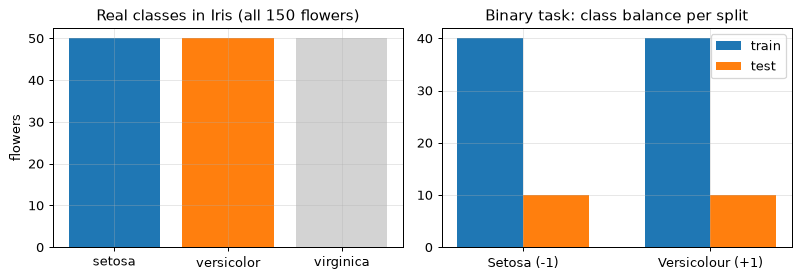

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
cnt = df["target"].map(dict(enumerate(iris.target_names))).value_counts().reindex(iris.target_names)
ax[0].bar(cnt.index, cnt.values, color=["tab:blue", "tab:orange", "lightgrey"])
ax[0].set_title("Real classes in Iris (all 150 flowers)"); ax[0].set_ylabel("flowers")
lab = {-1: "Setosa (-1)", 1: "Versicolour (+1)"}
w = 0.35
for j, (name, yy) in enumerate([("train", ytr), ("test", yte)]):
    ax[1].bar(np.arange(2) + (j - 0.5) * w, [np.sum(yy == -1), np.sum(yy == 1)], w, label=name)
ax[1].set_xticks(range(2)); ax[1].set_xticklabels([lab[-1], lab[1]])
ax[1].set_title("Binary task: class balance per split"); ax[1].legend()
plt.tight_layout(); plt.show()

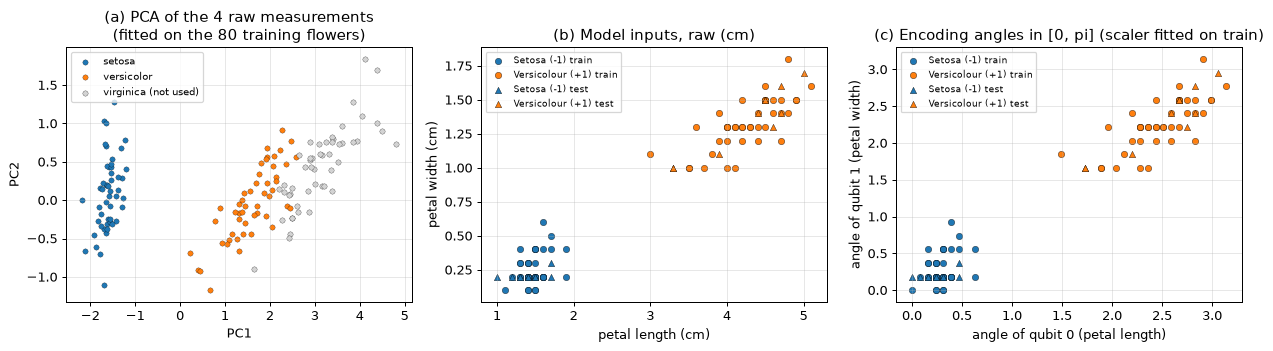

In [6]:
# 2-D views of the real flowers, coloured by ground-truth species.
col = {-1: "tab:blue", 1: "tab:orange"}
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

# (a) PCA of all four measurements, fitted on the training flowers only; Virginica (not used by the task) in grey
four = list(iris.feature_names)
tr_idx = sub.index.to_numpy()
Xfour_all = df[four].to_numpy(float)
Xfour_sub = sub[four].to_numpy(float)
Xf_tr, Xf_te = train_test_split(Xfour_sub, test_size=TEST_SIZE, stratify=yb, random_state=SEED)
pca = PCA(n_components=2, random_state=SEED).fit(Xf_tr)
P_all = pca.transform(Xfour_all)
sp = df["target"].to_numpy()
for k, nm, c in zip(range(3), iris.target_names, ["tab:blue", "tab:orange", "lightgrey"]):
    ax[0].scatter(*P_all[sp == k].T, s=18, c=c, label=nm + (" (not used)" if k == 2 else ""), edgecolor="k", linewidth=0.2)
ax[0].set_title("(a) PCA of the 4 raw measurements\n(fitted on the 80 training flowers)")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=8)

# (b) the two raw model features (cm)
for yy, XX, mk, nm in [(ytr, Xraw_tr, "o", "train"), (yte, Xraw_te, "^", "test")]:
    for c in (-1, 1):
        ax[1].scatter(*XX[yy == c].T, s=26, c=col[c], marker=mk, edgecolor="k", linewidth=0.3,
                      label=f"{lab[c]} {nm}")
ax[1].set_title("(b) Model inputs, raw (cm)"); ax[1].set_xlabel(FEATS[0]); ax[1].set_ylabel(FEATS[1]); ax[1].legend(fontsize=7)

# (c) the same two features after scaling to [0,1] and multiplying by pi = the rotation angles RX(pi x) of the circuit
for yy, XX, mk, nm in [(ytr, Xtr, "o", "train"), (yte, Xte, "^", "test")]:
    for c in (-1, 1):
        ax[2].scatter(*(np.pi * XX[yy == c]).T, s=26, c=col[c], marker=mk, edgecolor="k", linewidth=0.3,
                      label=f"{lab[c]} {nm}")
ax[2].set_title("(c) Encoding angles in [0, pi] (scaler fitted on train)")
ax[2].set_xlabel("angle of qubit 0 (petal length)"); ax[2].set_ylabel("angle of qubit 1 (petal width)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 1. The QNN, the noise model and a fast exact simulator

**Circuit (executed for every example).** `RX(pi x0)` on qubit 0 and `RX(pi x1)` on qubit 1 encode the two features;
`RY(t0)`, `RY(t1)`, a CNOT and `RY(t2)`, `RY(t3)` are the trainable part; the output is `g(x) = <Z_0>`.
Noise: after every gate a **depolarising channel** (`rho -> (1-lambda) rho + lambda I/2^k`), with
`lambda = 5 %` after 1-qubit gates and `10 %` after the CNOT (the paper's rates).

We need the output of this circuit for thousands of (example, parameter) pairs, so the notebook contains two
implementations that are asserted equal in section 3:

* a **PennyLane `default.mixed` QNode** (density-matrix simulator): this is the circuit that is drawn in the next
  section and that is the reference;
* a **vectorised NumPy density-matrix engine** used for training and the attack experiments.

Shots are then drawn from the exact output probability, which is what an ideal sampler returns.

In [7]:
# ---------------- vectorised exact density-matrix engine (2 qubits, wire 0 is the most significant bit) ----------------
PAULI = np.array([[[1, 0], [0, 1]], [[0, 1], [1, 0]], [[0, -1j], [1j, 0]], [[1, 0], [0, -1]]], dtype=complex)  # I X Y Z
I2 = np.eye(2, dtype=complex)
P1_Q0 = np.stack([np.kron(P, I2) for P in PAULI])            # Pauli on wire 0
P1_Q1 = np.stack([np.kron(I2, P) for P in PAULI])            # Pauli on wire 1
P2_ALL = np.stack([np.kron(a, b) for a in PAULI for b in PAULI])   # 16 two-qubit Paulis, index 4*a+b
CX_M = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)  # control wire 0, target wire 1

def _rot(axis, a):
    c = np.cos(a / 2)[:, None, None]; s = np.sin(a / 2)[:, None, None]
    return c * I2 - 1j * s * axis

def _kron_b(A, B):
    return np.einsum("bij,bkl->bikjl", A, B).reshape(-1, 4, 4)

def _conj(U, rho):
    return U @ rho @ np.conj(np.swapaxes(U, -1, -2))

def _dep1(rho, q, lam):
    """Depolarising channel (1-lam) rho + lam I/2 on qubit q."""
    if lam == 0:
        return rho
    r5 = rho.reshape(-1, 2, 2, 2, 2)                          # (b, i0, i1, j0, j1)
    if q == 0:
        red = np.einsum("baiaj->bij", r5); full = np.einsum("bij,ac->baicj", red, np.eye(2))
    else:
        red = np.einsum("baici->bac", r5); full = np.einsum("bac,ij->baicj", red, np.eye(2))
    return (1 - lam) * rho + (lam / 2) * full.reshape(-1, 4, 4)

def _dep2(rho, lam):
    if lam == 0:
        return rho
    tr = np.trace(rho, axis1=1, axis2=2)[:, None, None]
    return (1 - lam) * rho + lam * tr * np.eye(4) / 4

def _noise1(rho, q, lam, paulis, loc):
    rho = _dep1(rho, q, lam)
    if paulis is not None:                                    # PEC: insert a Pauli after the noisy gate
        T = (P1_Q0 if q == 0 else P1_Q1)[paulis[loc]]
        rho = _conj(T, rho)
    return rho

def evolve(X, TH, l1, l2, paulis=None):
    """Final density matrices (B,4,4) for inputs X (B,2) and parameters TH (B,4).
    paulis: optional list of 7 integer arrays (B,), the PEC Pauli inserted after each noisy gate
    (locations: enc q0, enc q1, ry q0, ry q1, cx (0..15), ry2 q0, ry2 q1)."""
    B = X.shape[0]
    rho = np.zeros((B, 4, 4), complex); rho[:, 0, 0] = 1
    rho = _conj(_kron_b(_rot(PAULI[1], np.pi * X[:, 0]), _rot(PAULI[1], np.pi * X[:, 1])), rho)
    rho = _noise1(rho, 0, l1, paulis, 0); rho = _noise1(rho, 1, l1, paulis, 1)
    rho = _conj(_kron_b(_rot(PAULI[2], TH[:, 0]), _rot(PAULI[2], TH[:, 1])), rho)
    rho = _noise1(rho, 0, l1, paulis, 2); rho = _noise1(rho, 1, l1, paulis, 3)
    rho = _conj(CX_M[None], rho)
    rho = _dep2(rho, l2)
    if paulis is not None:
        rho = _conj(P2_ALL[paulis[4]], rho)
    rho = _conj(_kron_b(_rot(PAULI[2], TH[:, 2]), _rot(PAULI[2], TH[:, 3])), rho)
    rho = _noise1(rho, 0, l1, paulis, 5); rho = _noise1(rho, 1, l1, paulis, 6)
    return rho

def expZ0(rho):
    d = np.real(np.einsum("bii->bi", rho))
    return d[:, 0] + d[:, 1] - d[:, 2] - d[:, 3]

def purity(rho):
    return np.real(np.einsum("bij,bji->b", rho, rho))

def out_ideal(X, TH):  return expZ0(evolve(X, TH, 0.0, 0.0))
def out_noisy(X, TH, l1=LAM1, l2=LAM2):  return expZ0(evolve(X, TH, l1, l2))
print("engine ready")

engine ready


In [8]:
# ---------------- the PennyLane QNode (reference circuit, with the noise channels as real operations) ----------------
dev = qml.device("default.mixed", wires=2)

def kraus_depol2(lam):
    """Kraus operators of rho -> (1-lam) rho + lam I/4 (two-qubit depolarising channel)."""
    return [np.sqrt(1 - 15 * lam / 16) * np.eye(4)] + [np.sqrt(lam / 16) * P for P in P2_ALL[1:]]

_P1 = [qml.Identity, qml.PauliX, qml.PauliY, qml.PauliZ]

def build_qnode(l1, l2, paulis=None):
    """paulis: None, or 7 integers (PEC variant: one Pauli inserted after each noisy gate)."""
    p1 = 3 * l1 / 4                                           # qml.DepolarizingChannel(p) equals lambda = 4p/3
    def noise1(w, loc):
        if l1 > 0:
            qml.DepolarizingChannel(p1, wires=w)
        if paulis is not None and paulis[loc] != 0:
            _P1[paulis[loc]](wires=w)
    @qml.qnode(dev)
    def circuit(x, th):
        qml.RX(np.pi * x[0], wires=0); qml.RX(np.pi * x[1], wires=1); noise1(0, 0); noise1(1, 1)
        qml.RY(th[0], wires=0); qml.RY(th[1], wires=1); noise1(0, 2); noise1(1, 3)
        qml.CNOT(wires=[0, 1])
        if l2 > 0:
            qml.QubitChannel(kraus_depol2(l2), wires=[0, 1])
        if paulis is not None and paulis[4] != 0:
            a, b = divmod(int(paulis[4]), 4)
            if a: _P1[a](wires=0)
            if b: _P1[b](wires=1)
        qml.RY(th[2], wires=0); qml.RY(th[3], wires=1); noise1(0, 5); noise1(1, 6)
        return qml.expval(qml.PauliZ(0))
    return circuit

qnode_ideal = build_qnode(0.0, 0.0)
qnode_noisy = build_qnode(LAM1, LAM2)
print("QNodes ready")

QNodes ready


## Quantum Circuit Architecture

The drawings below are produced by `qml.draw_mpl` from the **same QNodes that the verification in section 3 runs**.
Boxes labelled `DepolarizingChannel` / `QubitChannel` are the noise channels that are part of the executed circuit.
There are three distinct circuits: the ideal one, the noisy one (the device), and one **PEC variant** in which a
Pauli operation, drawn from the quasi-probability distribution, is inserted after each noisy gate. Assumptions where
the paper omits details (its Fig. 1 is not available in the extracted text): angle encoding `RX(pi x)`, ansatz
`RY - CNOT - RY` (the structure of Qiskit's `RealAmplitudes(2, reps=1)`), observable `Z` on qubit 0, depolarising
noise after every gate.

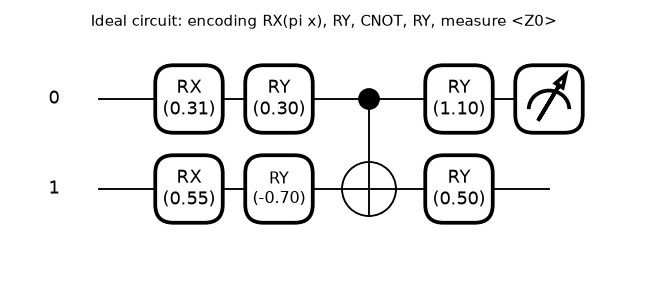

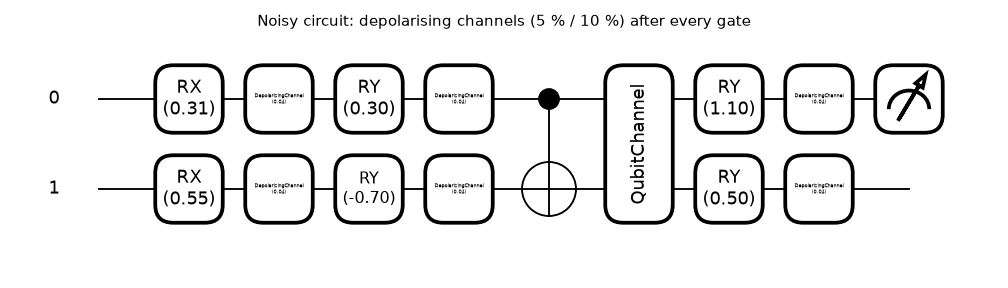

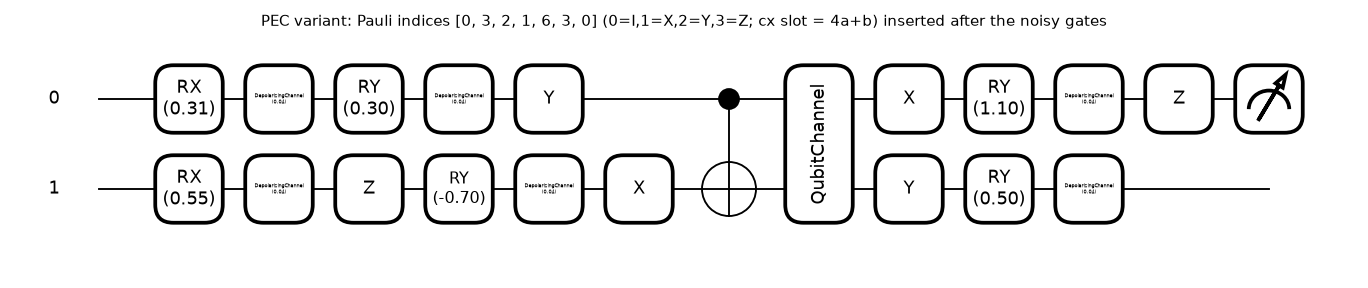

ideal circuit: {'n_qubits': 2, 'n_operations': 7, 'depth': 4}
noisy circuit: {'n_qubits': 2, 'n_operations': 14, 'depth': 8}
trainable parameters: 4 (t0..t3); data-encoding angles: 2 (pi*x0, pi*x1); observable: Z on qubit 0


In [9]:
x0 = Xtr[0]; th0 = np.array([0.3, -0.7, 1.1, 0.5])
fig, _ = qml.draw_mpl(qnode_ideal, decimals=2)(x0, th0)
fig.suptitle("Ideal circuit: encoding RX(pi x), RY, CNOT, RY, measure <Z0>"); plt.show()
fig, _ = qml.draw_mpl(qnode_noisy, decimals=2)(x0, th0)
fig.suptitle("Noisy circuit: depolarising channels (5 % / 10 %) after every gate"); plt.show()
rng_draw = np.random.default_rng(SEED)
pec_example = [int(rng_draw.integers(0, 4)) for _ in range(4)] + [int(rng_draw.integers(0, 16))] + [int(rng_draw.integers(0, 4)) for _ in range(2)]
fig, _ = qml.draw_mpl(build_qnode(LAM1, LAM2, paulis=pec_example), decimals=2)(x0, th0)
fig.suptitle(f"PEC variant: Pauli indices {pec_example} (0=I,1=X,2=Y,3=Z; cx slot = 4a+b) inserted after the noisy gates"); plt.show()

def tape_stats(qn):
    tape = qml.workflow.construct_batch(qn, level=0)(x0, th0)[0][0]
    ops = tape.operations
    return dict(n_qubits=len(tape.wires), n_operations=len(ops), depth=tape.graph.get_depth())
print("ideal circuit:", tape_stats(qnode_ideal))
print("noisy circuit:", tape_stats(qnode_noisy))
print("trainable parameters: 4 (t0..t3); data-encoding angles: 2 (pi*x0, pi*x1); observable: Z on qubit 0")

## 2. Probabilistic error cancellation (PEC) and the shot-noise estimators

**Shot noise.** Measuring `Z_0` `n` times returns `n` values in {-1, +1}. With mean `m = <Z_0>` the sample mean has
variance `(1 - m^2)/n` and, by the central limit theorem, is approximately Gaussian (paper, section III-A).

**PEC for depolarising gates.** A depolarising channel with error `lambda` multiplies every non-identity Pauli by
`f = 1 - lambda`. Its inverse is a Pauli "channel" with a quasi-probability distribution
`q_0 = 1 - (d^2-1) q_k`, `q_k = (1 - 1/f)/d^2` (`d = 2` for one qubit, `d = 4` for two qubits). Running the *noisy* gate
followed by a Pauli `P` drawn with probability `|q_P|/gamma_gate` and weighting the outcome with
`gamma_gate * sign(q_P)` removes the noise, in expectation. With `gamma = prod_gates gamma_gate` every single PEC shot is
therefore either `+gamma` or `-gamma`, and the mean is the **ideal** (noise-free) expectation. This is the
quasi-probability representation of the paper's Eq. (9)-(10); `sum_i |eta_i|^2` of Eq. (13) is the product over gates of
`sum_P q_P^2`. The estimator of `n` PEC shots is `gamma (2 Binomial(n, (1 + m/gamma)/2)/n - 1)`: section 3 checks that this
closed form is exactly what the circuit-variant sampling gives.

In [10]:
def pec_gate(lam, d2):
    f = 1.0 - lam
    qk = (1.0 - 1.0 / f) / d2
    q0 = 1.0 - (d2 - 1) * qk
    return dict(q0=q0, qk=qk, gamma=abs(q0) + (d2 - 1) * abs(qk), sq=q0 ** 2 + (d2 - 1) * qk ** 2)

def pec_constants(l1, l2):
    """6 one-qubit noisy gates and 1 two-qubit noisy gate per circuit."""
    g1, g2 = pec_gate(l1, 4), pec_gate(l2, 16)
    return dict(g1=g1, g2=g2, gamma=g1["gamma"] ** 6 * g2["gamma"], sumeta2=g1["sq"] ** 6 * g2["sq"])

PEC = pec_constants(LAM1, LAM2)
GAMMA = PEC["gamma"]
print(f"PEC at (lambda1, lambda2) = ({LAM1}, {LAM2}): gamma = {GAMMA:.3f}, sum|eta|^2 (Eq. 13 factor) = {PEC['sumeta2']:.3f}, "
      f"sampling overhead gamma^2 = {GAMMA**2:.2f}")

def estimate(m_noisy, m_ideal, n, mode, rng, gamma=None):
    """One finite-shot estimate of g(x) for each entry.  modes: ideal (exact), shots (ideal device), noisy, pec."""
    if mode == "ideal":
        return m_ideal
    if mode == "shots":
        p = (1 + m_ideal) / 2; sc = 1.0
    elif mode == "noisy":
        p = (1 + m_noisy) / 2; sc = 1.0
    elif mode == "pec":
        p = (1 + m_ideal / gamma) / 2; sc = gamma
    else:
        raise ValueError(mode)
    p = np.clip(p, 0.0, 1.0)
    return sc * (2.0 * rng.binomial(n, p) / n - 1.0)

SHIFTS = np.zeros((8, 4))
for _k in range(4):
    SHIFTS[2 * _k, _k] = np.pi / 2; SHIFTS[2 * _k + 1, _k] = -np.pi / 2

def shifted_means(th, X, l1=LAM1, l2=LAM2, need_noisy=True):
    """Exact ideal / noisy expectations at the 8 parameter-shifted circuits for every example: arrays (8, N)."""
    N = len(X)
    THb = np.repeat(th[None, :] + SHIFTS, N, axis=0)
    Xb = np.tile(X, (8, 1))
    mi = out_ideal(Xb, THb).reshape(8, N)
    mn = out_noisy(Xb, THb, l1, l2).reshape(8, N) if need_noisy else None
    return mi, mn

def per_example_grads(X, y, th, mode, n, rng, l1=LAM1, l2=LAM2, gamma=None, cache=None):
    """Parameter-shift gradient of the modified hinge loss l = 1 - y g(x) for every example: (N, 4).
    Each of the 8 shifted circuits is a separate execution with its own shot noise."""
    mi, mn = cache if cache is not None else shifted_means(th, X, l1, l2, need_noisy=(mode in ("noisy", "pec")))
    est = estimate(mn, mi, n, mode, rng, gamma)
    return (-0.5 * y[None, :] * (est[0::2] - est[1::2])).T

def clip_rows(G, C):
    nrm = np.linalg.norm(G, axis=1, keepdims=True)
    return G * np.minimum(1.0, C / np.maximum(nrm, 1e-12))

def predict_acc(X, y, th, mode, n, rng, l1=LAM1, l2=LAM2, gamma=None):
    TH = np.tile(th, (len(X), 1))
    mi = out_ideal(X, TH)
    mn = out_noisy(X, TH, l1, l2) if mode in ("noisy", "pec") else None
    est = estimate(mn, mi, n, mode, rng, gamma)
    return float(np.mean(np.where(est >= 0, 1, -1) == y))

def ideal_loss(X, y, th):
    return float(np.mean(1 - y * out_ideal(X, np.tile(th, (len(X), 1)))))
print("estimators ready")

PEC at (lambda1, lambda2) = (0.05, 0.1): gamma = 1.906, sum|eta|^2 (Eq. 13 factor) = 1.947, sampling overhead gamma^2 = 3.63
estimators ready


## 3. Verifying the simulators and PEC

Four checks, all with explicit assertions:

1. the NumPy engine equals the PennyLane `default.mixed` QNode (exact, ideal and noisy, plus a PEC variant);
2. the same noisy circuit run with a **Qiskit Aer** noise model (`depolarizing_error` on `rx`, `ry`, `cx`, density-matrix
   method) gives the same expectation;
3. PennyLane finite-shot readout has the mean and variance `(1 - m^2)/n` that the estimators assume;
4. PEC: sampling circuit variants from the quasi-probability distribution and weighting them reproduces the **ideal**
   expectation, and a single PEC shot follows the two-point law on `{-gamma, +gamma}`.

In [11]:
rng_v = np.random.default_rng(SEED + 1)
errs_pl, errs_aer = [], []
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.quantum_info import DensityMatrix, SparsePauliOp

def aer_expZ0(x, th, l1, l2):
    qc = QuantumCircuit(2)
    qc.rx(np.pi * x[0], 0); qc.rx(np.pi * x[1], 1)
    qc.ry(th[0], 0); qc.ry(th[1], 1); qc.cx(0, 1); qc.ry(th[2], 0); qc.ry(th[3], 1)
    qc.save_density_matrix()
    nm = NoiseModel(basis_gates=["rx", "ry", "cx"])
    if l1 > 0: nm.add_all_qubit_quantum_error(depolarizing_error(l1, 1), ["rx", "ry"])
    if l2 > 0: nm.add_all_qubit_quantum_error(depolarizing_error(l2, 2), ["cx"])
    sim = AerSimulator(method="density_matrix", noise_model=nm)
    dm = sim.run(transpile(qc, sim, optimization_level=0)).result().data(0)["density_matrix"]
    dm = DensityMatrix(dm)
    return float(np.real(dm.expectation_value(SparsePauliOp("IZ")))), float(np.real(dm.purity()))

rows = []
for _ in range(N_VERIFY):
    x = rng_v.random(2); th = rng_v.uniform(-np.pi, np.pi, 4)
    for (l1, l2) in [(0.0, 0.0), (LAM1, LAM2), (2 * LAM1, 2 * LAM2)]:
        eng = float(expZ0(evolve(x[None], th[None], l1, l2))[0])
        eng_pur = float(purity(evolve(x[None], th[None], l1, l2))[0])
        pl = float(build_qnode(l1, l2)(x, th))
        aer, aer_pur = aer_expZ0(x, th, l1, l2)
        errs_pl.append(abs(eng - pl)); errs_aer.append(max(abs(eng - aer), abs(eng_pur - aer_pur)))
        rows.append((l1, l2, eng, pl, aer))
# PEC variant circuit: engine vs PennyLane QNode with the inserted Paulis
pv = [int(rng_v.integers(0, 4)) for _ in range(4)] + [int(rng_v.integers(0, 16))] + [int(rng_v.integers(0, 4)) for _ in range(2)]
x = rng_v.random(2); th = rng_v.uniform(-np.pi, np.pi, 4)
eng_v = float(expZ0(evolve(x[None], th[None], LAM1, LAM2, paulis=[np.array([p]) for p in pv]))[0])
pl_v = float(build_qnode(LAM1, LAM2, paulis=pv)(x, th))
print(pd.DataFrame(rows, columns=["lambda1", "lambda2", "numpy engine", "PennyLane default.mixed", "Qiskit Aer"]).round(10).head(9).to_string(index=False))
print(f"max |engine - PennyLane| = {max(errs_pl):.2e}   max |engine - Aer| (expectation and purity) = {max(errs_aer):.2e}   "
      f"PEC variant |engine - PennyLane| = {abs(eng_v - pl_v):.2e}")
assert max(errs_pl) < 1e-9 and abs(eng_v - pl_v) < 1e-9, "engine disagrees with PennyLane"
assert max(errs_aer) < 1e-7, "engine disagrees with Qiskit Aer"
print("OK: NumPy density-matrix engine == PennyLane default.mixed == Qiskit Aer noise model")

 lambda1  lambda2  numpy engine  PennyLane default.mixed  Qiskit Aer
    0.00      0.0      0.364757                 0.364757    0.364757
    0.05      0.1      0.283359                 0.283359    0.283359
    0.10      0.2      0.215523                 0.215523    0.215523
    0.00      0.0      0.618115                 0.618115    0.618115
    0.05      0.1      0.475499                 0.475499    0.475499
    0.10      0.2      0.358331                 0.358331    0.358331
    0.00      0.0      0.209161                 0.209161    0.209161
    0.05      0.1      0.161049                 0.161049    0.161049
    0.10      0.2      0.121471                 0.121471    0.121471
max |engine - PennyLane| = 6.75e-14   max |engine - Aer| (expectation and purity) = 9.99e-16   PEC variant |engine - PennyLane| = 1.35e-14
OK: NumPy density-matrix engine == PennyLane default.mixed == Qiskit Aer noise model


exact <Z0> = -0.2437; PennyLane 500 runs x 10 shots: mean = -0.2312 (theory +- 0.0137), variance = 0.1011 (theory 0.0941)


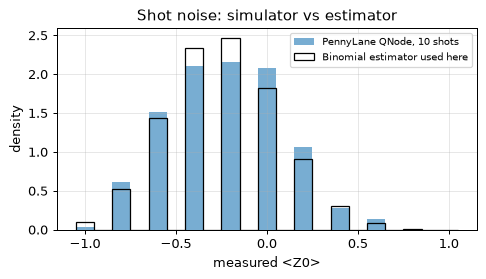

OK: shot statistics match


In [12]:
# Check 3: finite-shot readout of the PennyLane QNode follows the Binomial law assumed by the estimators.
x = Xtr[3]; th = np.array([0.4, -1.2, 0.9, 0.2]); n_chk = 10
qn_shots = qml.set_shots(build_qnode(LAM1, LAM2), shots=n_chk)
vals = np.array([float(qn_shots(x, th)) for _ in range(SHOT_CHECK_RUNS)])
m_exact = float(expZ0(evolve(x[None], th[None], LAM1, LAM2))[0])
var_th = (1 - m_exact ** 2) / n_chk
se_mean = math.sqrt(var_th / SHOT_CHECK_RUNS)
print(f"exact <Z0> = {m_exact:.4f}; PennyLane {SHOT_CHECK_RUNS} runs x {n_chk} shots: mean = {vals.mean():.4f} (theory +- {se_mean:.4f}), "
      f"variance = {vals.var(ddof=1):.4f} (theory {var_th:.4f})")
assert abs(vals.mean() - m_exact) < 4.5 * se_mean
assert abs(vals.var(ddof=1) / var_th - 1) < 0.35
sim_vals = 2 * np.random.default_rng(SEED).binomial(n_chk, (1 + m_exact) / 2, 20000) / n_chk - 1
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bins = np.linspace(-1.05, 1.05, 22)
ax.hist(vals, bins=bins, density=True, alpha=0.6, label=f"PennyLane QNode, {n_chk} shots")
ax.hist(sim_vals, bins=bins, density=True, histtype="step", color="k", label="Binomial estimator used here")
ax.set_xlabel("measured <Z0>"); ax.set_ylabel("density"); ax.set_title("Shot noise: simulator vs estimator"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("OK: shot statistics match")

ideal <Z0> = 0.4253 | noisy device = 0.3098 | PEC-weighted mean over 60000 variants = 0.4242 +- 0.0015
single PEC shot: P(+gamma) = 0.6092; two-point law (1 + m/gamma)/2 = 0.6115; shot mean 0.4162, shot variance 3.461 vs gamma^2 - m^2 = 3.453


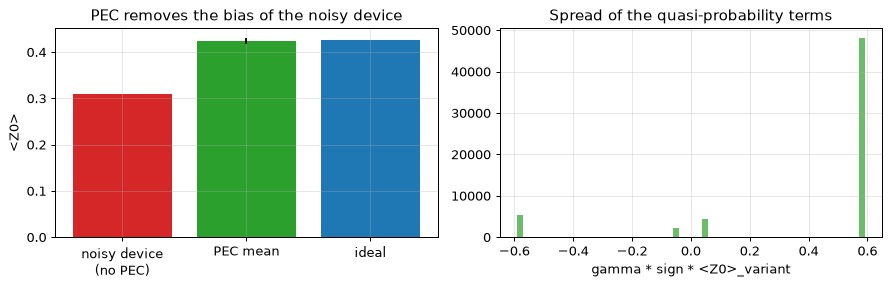

OK: PEC reproduces the ideal expectation; single-shot law confirmed


In [13]:
# Check 4: PEC.  Sample circuit variants (one Pauli after each noisy gate) from |q|/gamma, run each EXACTLY (noisy engine),
# weight by gamma * sign, and compare with the ideal expectation.  Then draw single shots and compare with the two-point law.
rng_p = np.random.default_rng(SEED + 2)
g1, g2 = PEC["g1"], PEC["g2"]
V = 60000
def sample_variant(V, rng):
    p1 = np.array([abs(g1["q0"])] + [abs(g1["qk"])] * 3) / g1["gamma"]
    p2 = np.array([abs(g2["q0"])] + [abs(g2["qk"])] * 15) / g2["gamma"]
    s1 = np.array([np.sign(g1["q0"])] + [np.sign(g1["qk"])] * 3)
    s2 = np.array([np.sign(g2["q0"])] + [np.sign(g2["qk"])] * 15)
    P = [rng.choice(4, size=V, p=p1) for _ in range(4)] + [rng.choice(16, size=V, p=p2)] + [rng.choice(4, size=V, p=p1) for _ in range(2)]
    sign = np.prod([s1[P[j]] for j in (0, 1, 2, 3, 5, 6)], axis=0) * s2[P[4]]
    return P, sign

xs = Xtr[5]; ths = np.array([0.8, -0.4, 1.3, -0.9])
P, sign = sample_variant(V, rng_p)
m_var = expZ0(evolve(np.tile(xs, (V, 1)), np.tile(ths, (V, 1)), LAM1, LAM2, paulis=P))     # exact <Z0> of each variant
est_terms = GAMMA * sign * m_var
m_ideal_s = float(out_ideal(xs[None], ths[None])[0]); m_noisy_s = float(out_noisy(xs[None], ths[None])[0])
pec_mean, pec_se = est_terms.mean(), est_terms.std(ddof=1) / math.sqrt(V)
print(f"ideal <Z0> = {m_ideal_s:.4f} | noisy device = {m_noisy_s:.4f} | PEC-weighted mean over {V} variants = {pec_mean:.4f} +- {pec_se:.4f}")
assert abs(pec_mean - m_ideal_s) < 4.5 * pec_se, "PEC does not recover the ideal expectation"
# single PEC shots: outcome o in {-1,+1} with prob (1+m_variant)/2, value = gamma * sign * o
o = np.where(rng_p.random(V) < (1 + m_var) / 2, 1.0, -1.0)
shots_vals = GAMMA * sign * o
frac_plus = float(np.mean(shots_vals > 0)); p_th = (1 + m_ideal_s / GAMMA) / 2
print(f"single PEC shot: P(+gamma) = {frac_plus:.4f}; two-point law (1 + m/gamma)/2 = {p_th:.4f}; shot mean {shots_vals.mean():.4f}, "
      f"shot variance {shots_vals.var():.3f} vs gamma^2 - m^2 = {GAMMA**2 - m_ideal_s**2:.3f}")
assert abs(frac_plus - p_th) < 4.5 * math.sqrt(p_th * (1 - p_th) / V)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].bar(["noisy device\n(no PEC)", "PEC mean", "ideal"], [m_noisy_s, pec_mean, m_ideal_s], yerr=[0, 4.5 * pec_se, 0], color=["tab:red", "tab:green", "tab:blue"])
ax[0].set_ylabel("<Z0>"); ax[0].set_title("PEC removes the bias of the noisy device")
ax[1].hist(est_terms, bins=60, color="tab:green", alpha=0.7); ax[1].set_xlabel("gamma * sign * <Z0>_variant")
ax[1].set_title("Spread of the quasi-probability terms")
plt.tight_layout(); plt.show()
print("OK: PEC reproduces the ideal expectation; single-shot law confirmed")

## 4. Effect of incoherent noise and of PEC on training (paper Fig. 2)

Three pipelines train the same QNN (same initial parameters per seed, plain gradient descent on the modified hinge loss,
gradients by the parameter-shift rule, `SHOTS_TRAIN` shots per circuit):

* **ideal**: noise-free exact gradients (reference);
* **noisy**: the noisy device, no mitigation;
* **PEC**: the noisy device with probabilistic error cancellation.

The paper gives learning rate 0.01 but not how the per-example gradients are combined or how many iterations are run, so
two readings are trained (`# CHOICE`), because the effect of the noise depends on how fast training is:

* **fast regime** (used everywhere else in this notebook): update `lr x sum_i grad_i` (lr per example, one iteration = one
  epoch of per-example SGD in the small-step limit);
* **slow regime** (literal reading): update `lr x mean_i grad_i`, a budget of `2 x T_ITERS` iterations.

We track the exact noise-free loss of the current parameters and the test accuracy that each pipeline would measure
(`SHOTS_EVAL` shots), averaged over `N_SEEDS` initialisations.

trained 3 pipelines x 10 seeds, fast regime (300 it.) and slow regime (600 it.) in 941.9 s


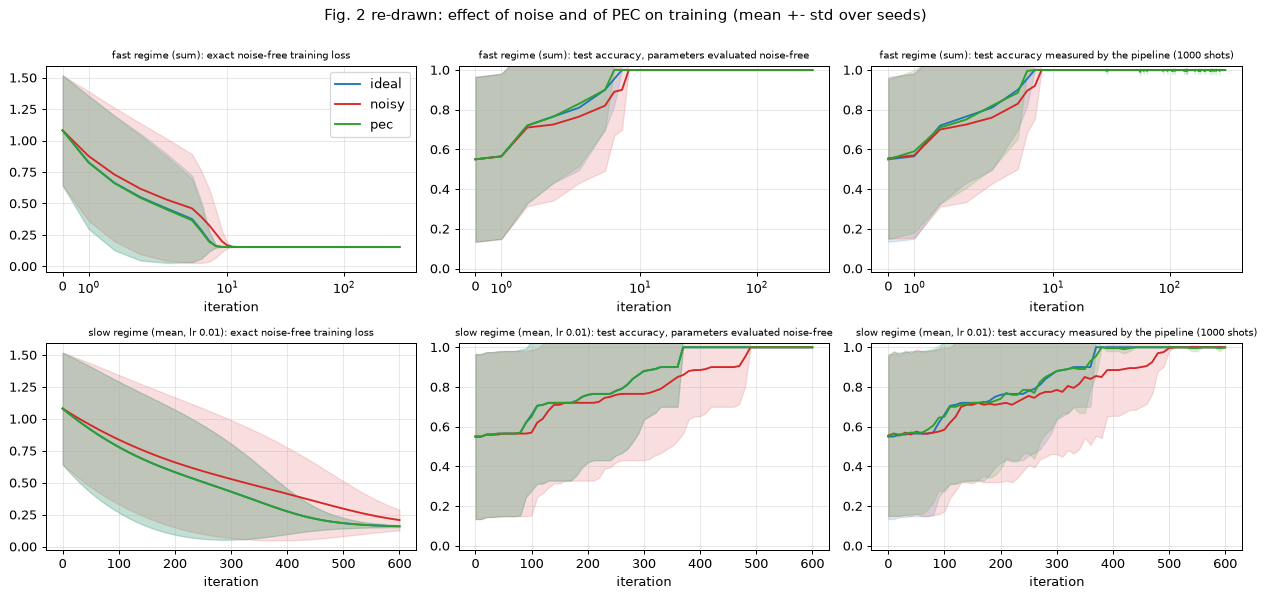

fast regime:
       final_loss  mean_loss_over_run  acc_noise_free  acc_pipeline  acc_pipeline_sd
ideal       0.154               0.165             1.0           1.0              0.0
noisy       0.154               0.167             1.0           1.0              0.0
pec         0.154               0.164             1.0           1.0              0.0
slow regime:
       final_loss  mean_loss_over_run  acc_noise_free  acc_pipeline  acc_pipeline_sd
ideal       0.160               0.476             1.0           1.0              0.0
noisy       0.208               0.562             1.0           1.0              0.0
pec         0.160               0.476             1.0           1.0              0.0


In [14]:
def train_qnn(mode, seed, T, lr=LR, n=SHOTS_TRAIN, clip=None, z=None, eval_every=EVAL_EVERY, X=Xtr, y=ytr, l1=LAM1, l2=LAM2, gamma=GAMMA, track=True, agg="sum"):
    """Gradient descent.  agg: 'sum' (lr per example) or 'mean'.  clip/z: optional DP-SGD clipping norm and Gaussian noise multiplier."""
    rng = np.random.default_rng(seed)
    th = np.random.default_rng(1000 + seed).uniform(-np.pi, np.pi, 4)       # same init for every mode
    hist = []
    for t in range(T + 1):
        if track and t % eval_every == 0:
            hist.append((t, ideal_loss(X, y, th), predict_acc(Xte, yte, th, "ideal", 0, rng),
                         predict_acc(Xte, yte, th, mode, SHOTS_EVAL, rng, l1, l2, gamma)))
        if t == T:
            break
        G = per_example_grads(X, y, th, mode, n, rng, l1, l2, gamma)
        if clip is not None:
            G = clip_rows(G, clip)
        gs = G.sum(0)
        if z is not None:
            gs = gs + rng.normal(0.0, z * clip, size=4)
        th = th - lr * (gs if agg == "sum" else gs / len(G))      # CHOICE: sum (lr per example) or mean of the per-example gradients
    return th, np.array(hist)

t0 = time.time()
runs = {m: [train_qnn(m, s, T_ITERS) for s in range(N_SEEDS)] for m in ["ideal", "noisy", "pec"]}
T_LIT = 2 * T_ITERS
runs_lit = {m: [train_qnn(m, s, T_LIT, agg="mean", eval_every=10) for s in range(N_SEEDS)] for m in ["ideal", "noisy", "pec"]}
print(f"trained 3 pipelines x {N_SEEDS} seeds, fast regime ({T_ITERS} it.) and slow regime ({T_LIT} it.) in {time.time()-t0:.1f} s")
colors = {"ideal": "tab:blue", "noisy": "tab:red", "pec": "tab:green"}
def summarise(rr):
    HH = {m: np.stack([h for _, h in rr[m]]) for m in rr}                  # (seeds, evals, 4): t, loss, acc_ideal, acc_pipeline
    fn = {m: dict(final_loss=HH[m][:, -1, 1].mean(), mean_loss_over_run=HH[m][:, :, 1].mean(), acc_noise_free=HH[m][:, -1, 2].mean(),
                  acc_pipeline=HH[m][:, -1, 3].mean(), acc_pipeline_sd=HH[m][:, -1, 3].std()) for m in HH}
    return HH, fn
H, fin = summarise(runs)
H_lit, fin_lit = summarise(runs_lit)
fig, ax = plt.subplots(2, 3, figsize=(14, 6.6))
for r_, (HH, ttl_) in enumerate([(H, "fast regime (sum)"), (H_lit, "slow regime (mean, lr 0.01)")]):
    its = HH["ideal"][0, :, 0]
    for m in HH:
        for j, (idx, ttl) in enumerate([(1, "exact noise-free training loss"), (2, "test accuracy, parameters evaluated noise-free"),
                                        (3, f"test accuracy measured by the pipeline ({SHOTS_EVAL} shots)")]):
            mu, sd = HH[m][:, :, idx].mean(0), HH[m][:, :, idx].std(0)
            ax[r_, j].plot(its, mu, color=colors[m], label=m); ax[r_, j].fill_between(its, mu - sd, mu + sd, color=colors[m], alpha=0.15)
            ax[r_, j].set_title(f"{ttl_}: {ttl}", fontsize=8); ax[r_, j].set_xlabel("iteration")
            if r_ == 0: ax[r_, j].set_xscale("symlog", linthresh=5)
    ax[r_, 1].set_ylim(-0.02, 1.02); ax[r_, 2].set_ylim(-0.02, 1.02)
ax[0, 0].legend()
plt.suptitle("Fig. 2 re-drawn: effect of noise and of PEC on training (mean +- std over seeds)", y=1.0)
plt.tight_layout(); plt.show()
print("fast regime:"); print(pd.DataFrame(fin).T.round(3).to_string())
print("slow regime:"); print(pd.DataFrame(fin_lit).T.round(3).to_string())

## 5. The variance of the gradient: Gaussianity and Lemma 1 (paper Fig. 3)

For every training example the gradient of the modified hinge loss with respect to parameter `t_k` is
`-y * (1/2) [g(t + pi/2 e_k) - g(t - pi/2 e_k)]` (parameter-shift rule), a difference of two independent shot-noise
estimates. The paper's Lemma 1 bounds its variance by
`(sum|eta|^2 / 2) h_min <= Var <= (sum|eta|^2 / 2) h_max`.

Here `h(p_t, rho, n) = (1 - ((1-p_t) <Z>)^2)/n` is the variance of the *unmitigated* estimator under global depolarising
noise, `h_min` is taken at `|<Z>| = 1` and `h_max = 1/n` at `<Z> = 0`.
`p_t` is obtained from the purity of the simulated noisy output state with the paper's Eq. (7)
(`(1-p)^2 + 2p(1-p)/d + p^2/d = Tr rho^2`, `d = 4`), averaged over the training examples at the trained parameters.

Three things are checked: (i) is the global-depolarising picture a fair description of the per-gate noise?
(ii) is the gradient noise Gaussian? (iii) does the lower bound hold for the **exact** gradient variance of our PEC pipeline?

 scale     l1    l2    p_t  gamma  sumeta2
  0.25 0.0125 0.025 0.0746 1.1733   1.1748
  0.50 0.0250 0.050 0.1445 1.3779   1.3851
  0.75 0.0375 0.075 0.2100 1.6198   1.6390
  1.00 0.0500 0.100 0.2713 1.9063   1.9469
  1.50 0.0750 0.150 0.3823 2.6498   2.7802
  2.00 0.1000 0.200 0.4791 3.7036   4.0385


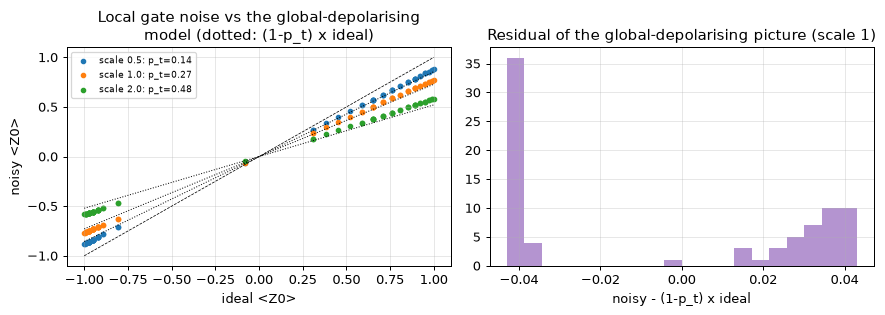

max residual of the global-depolarising picture at scale 1: 0.043 (outputs are in [-1, 1])


In [15]:
th_ref = runs["ideal"][0][0]                      # CHOICE: noise-free trained parameters of seed 0 are the reference point
A_PUR = 1 - 1 / 4                                  # (1 - 1/d) with d = 2^2

def noise_profile(scale, th=th_ref, X=Xtr):
    l1, l2 = scale * LAM1, scale * LAM2
    rho = evolve(X, np.tile(th, (len(X), 1)), l1, l2)
    P = purity(rho)
    pt = float(np.mean(1 - np.sqrt(np.clip(1 - (1 - P) / A_PUR, 0, None))))   # solves Eq. (7) for p_t
    c = pec_constants(l1, l2)
    mi, mn = shifted_means(th, X, l1, l2)
    fwd_i = out_ideal(X, np.tile(th, (len(X), 1))); fwd_n = out_noisy(X, np.tile(th, (len(X), 1)), l1, l2)
    return dict(scale=scale, l1=l1, l2=l2, p_t=pt, gamma=c["gamma"], sumeta2=c["sumeta2"], mi=mi, mn=mn, fwd_i=fwd_i, fwd_n=fwd_n)

PROF = {s: noise_profile(s) for s in sorted(set(NOISE_SCALES + [1.0]))}
prof1 = PROF[1.0]
print(pd.DataFrame([{k: v for k, v in p.items() if k in ("scale", "l1", "l2", "p_t", "gamma", "sumeta2")} for p in PROF.values()]).round(4).to_string(index=False))

# (i) global-depolarising picture: noisy <Z> vs (1 - p_t) * ideal <Z>
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for s in [0.5, 1.0, 2.0]:
    if s in PROF:
        p = PROF[s]; ax[0].scatter(p["fwd_i"], p["fwd_n"], s=12, label=f"scale {s}: p_t={p['p_t']:.2f}")
        ax[0].plot([-1, 1], [-(1 - p["p_t"]), 1 - p["p_t"]], "k:", lw=0.8)
ax[0].plot([-1, 1], [-1, 1], "k--", lw=0.6); ax[0].set_xlabel("ideal <Z0>"); ax[0].set_ylabel("noisy <Z0>")
ax[0].set_title("Local gate noise vs the global-depolarising\nmodel (dotted: (1-p_t) x ideal)"); ax[0].legend(fontsize=7)
resid = prof1["fwd_n"] - (1 - prof1["p_t"]) * prof1["fwd_i"]
ax[1].hist(resid, bins=20, color="tab:purple", alpha=0.7); ax[1].set_xlabel("noisy - (1-p_t) x ideal"); ax[1].set_title("Residual of the global-depolarising picture (scale 1)")
plt.tight_layout(); plt.show()
print(f"max residual of the global-depolarising picture at scale 1: {np.abs(resid).max():.3f} (outputs are in [-1, 1])")

 shots    mean    std  std_formula    skew  excess_kurtosis
    10 -0.0012 0.4259       0.4263  0.0037          -0.0710
   100  0.0010 0.1351       0.1348 -0.0069          -0.0095
  1000  0.0004 0.0425       0.0426  0.0146           0.0047


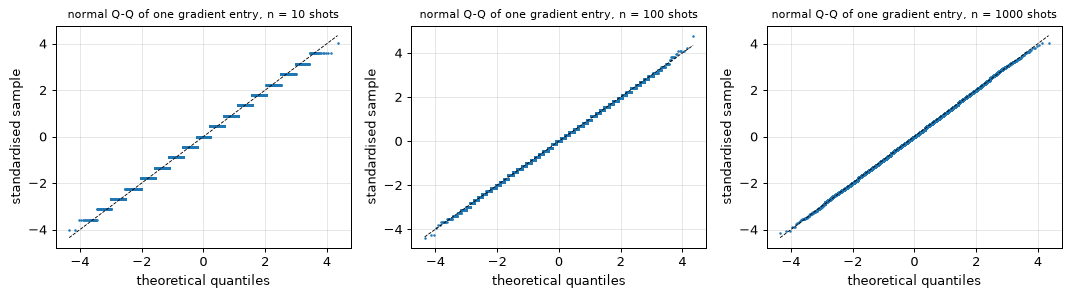

In [16]:
def sigma_paper_lower(n, p):  return math.sqrt(p["sumeta2"] * (1 - (1 - p["p_t"]) ** 2) / n / 2)
def sigma_paper_upper(n, p):  return math.sqrt(p["sumeta2"] * 1.0 / n / 2)
def sigma_emp_pec(n, p):
    """Exact std of every per-example gradient coordinate of the PEC pipeline (two-point shot law): (4, N)."""
    var = (2 * p["gamma"] ** 2 - p["mi"][0::2] ** 2 - p["mi"][1::2] ** 2) / (4 * n)
    return np.sqrt(var)
def sigma_emp_noisy(n, p):
    var = (2 - p["mn"][0::2] ** 2 - p["mn"][1::2] ** 2) / (4 * n)
    return np.sqrt(var)

# (ii) Gaussianity of one gradient coordinate, by Monte-Carlo with the PEC pipeline
rng_g = np.random.default_rng(SEED + 3)
gnorm = np.linalg.norm(-0.5 * ytr[:, None] * (prof1["mi"][0::2] - prof1["mi"][1::2]).T, axis=1)
i_ex = int(np.argsort(gnorm)[len(gnorm) // 2]); k_co = 0                      # median-gradient example, parameter t0
gauss_rows, qq = [], {}
for n in [10, 100, 1000]:
    pp = lambda m: np.clip((1 + m / GAMMA) / 2, 0, 1)
    gp = GAMMA * (2 * rng_g.binomial(n, pp(prof1["mi"][2 * k_co, i_ex]), GAUSS_DRAWS) / n - 1)
    gm = GAMMA * (2 * rng_g.binomial(n, pp(prof1["mi"][2 * k_co + 1, i_ex]), GAUSS_DRAWS) / n - 1)
    g = -0.5 * ytr[i_ex] * (gp - gm)
    gauss_rows.append(dict(shots=n, mean=g.mean(), std=g.std(), std_formula=sigma_emp_pec(n, prof1)[k_co, i_ex],
                           skew=stats.skew(g), excess_kurtosis=stats.kurtosis(g)))
    qq[n] = g
GAUSS = pd.DataFrame(gauss_rows)
print(GAUSS.round(4).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, n in zip(ax, [10, 100, 1000]):
    g = qq[n]; (osm, osr), (slope, icpt, r) = stats.probplot((g - g.mean()) / g.std(), dist="norm")
    a.plot(osm, osr, ".", ms=2); a.plot(osm, osm, "k--", lw=0.7); a.set_title(f"normal Q-Q of one gradient entry, n = {n} shots", fontsize=9)
    a.set_xlabel("theoretical quantiles"); a.set_ylabel("standardised sample")
plt.tight_layout(); plt.show()

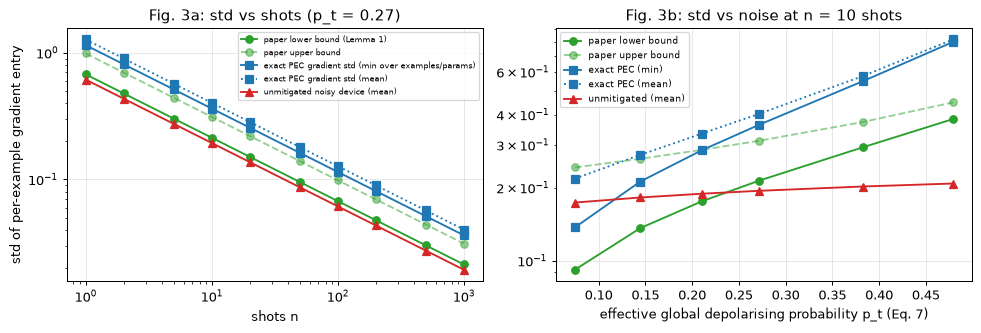

lower bound <= exact PEC std (all n, all noise levels): True; mean exact std <= upper bound: False
bound decreases with shots: True; bound increases with p_t: True
tightness at n = 10, scale 1: exact min std / paper lower bound = 1.70


In [17]:
# Fig. 3 re-drawn.  (a) std vs shots at the paper's noise; (b) std vs p_t at n = 10 shots.
ns = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
fa = dict(lo=[sigma_paper_lower(n, prof1) for n in ns], hi=[sigma_paper_upper(n, prof1) for n in ns],
          pec_min=[sigma_emp_pec(n, prof1).min() for n in ns], pec_mean=[sigma_emp_pec(n, prof1).mean() for n in ns],
          noisy_mean=[sigma_emp_noisy(n, prof1).mean() for n in ns])
scales_sorted = sorted(PROF)
pts = [PROF[s]["p_t"] for s in scales_sorted]
N10 = 10
fb = dict(lo=[sigma_paper_lower(N10, PROF[s]) for s in scales_sorted], hi=[sigma_paper_upper(N10, PROF[s]) for s in scales_sorted],
          pec_min=[sigma_emp_pec(N10, PROF[s]).min() for s in scales_sorted], pec_mean=[sigma_emp_pec(N10, PROF[s]).mean() for s in scales_sorted],
          noisy_mean=[sigma_emp_noisy(N10, PROF[s]).mean() for s in scales_sorted])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(ns, fa["lo"], "o-", label="paper lower bound (Lemma 1)", color="tab:green")
ax[0].loglog(ns, fa["hi"], "o--", label="paper upper bound", color="tab:green", alpha=0.5)
ax[0].loglog(ns, fa["pec_min"], "s-", label="exact PEC gradient std (min over examples/params)", color="tab:blue")
ax[0].loglog(ns, fa["pec_mean"], "s:", label="exact PEC gradient std (mean)", color="tab:blue")
ax[0].loglog(ns, fa["noisy_mean"], "^-", label="unmitigated noisy device (mean)", color="tab:red")
ax[0].set_xlabel("shots n"); ax[0].set_ylabel("std of per-example gradient entry"); ax[0].set_title(f"Fig. 3a: std vs shots (p_t = {prof1['p_t']:.2f})"); ax[0].legend(fontsize=6.5)
ax[1].semilogy(pts, fb["lo"], "o-", label="paper lower bound", color="tab:green")
ax[1].semilogy(pts, fb["hi"], "o--", label="paper upper bound", color="tab:green", alpha=0.5)
ax[1].semilogy(pts, fb["pec_min"], "s-", label="exact PEC (min)", color="tab:blue")
ax[1].semilogy(pts, fb["pec_mean"], "s:", label="exact PEC (mean)", color="tab:blue")
ax[1].semilogy(pts, fb["noisy_mean"], "^-", label="unmitigated (mean)", color="tab:red")
ax[1].set_xlabel("effective global depolarising probability p_t (Eq. 7)"); ax[1].set_title(f"Fig. 3b: std vs noise at n = {N10} shots"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
lower_ok = all(np.array(fa["pec_min"]) >= np.array(fa["lo"])) and all(np.array(fb["pec_min"]) >= np.array(fb["lo"]))
upper_ok = all(np.array(fa["pec_mean"]) <= np.array(fa["hi"])) and all(np.array(fb["pec_mean"]) <= np.array(fb["hi"]))
dec_shots = bool(np.all(np.diff(fa["lo"]) < 0))
inc_noise = bool(np.all(np.diff(fb["lo"]) > 0))
print(f"lower bound <= exact PEC std (all n, all noise levels): {lower_ok}; mean exact std <= upper bound: {upper_ok}")
print(f"bound decreases with shots: {dec_shots}; bound increases with p_t: {inc_noise}")
print(f"tightness at n = 10, scale 1: exact min std / paper lower bound = {fa['pec_min'][3] / fa['lo'][3]:.2f}")

## 6. From the variance bound to a privacy budget (paper Fig. 4)

Following Theorem 1 the noise scale of every gradient entry is `sigma_min`, the lower bound of Lemma 1. With the choices
made in the table at the top (`# CHOICE`): the released object of one step is the **sum over the batch of `B` per-example
gradients**; every example's gradient has its own independent quantum noise, so the sum has noise std `sigma_min sqrt(B)` while
one record changes the sum by at most the clipping norm `C = 0.7`. The noise multiplier is `z = sigma_min sqrt(B) / C`. The
Renyi-DP of `T` Gaussian steps is `T alpha / (2 z^2)`, converted to `(epsilon, delta)` with `delta = 0.01` by
`epsilon = min_alpha [T alpha / (2 z^2) + log(1/delta)/(alpha - 1)]`.

largest noise-free per-example gradient l2 norm over 60 random parameter vectors: 1.40; median of the maxima 1.04; clipping norm C = 0.7


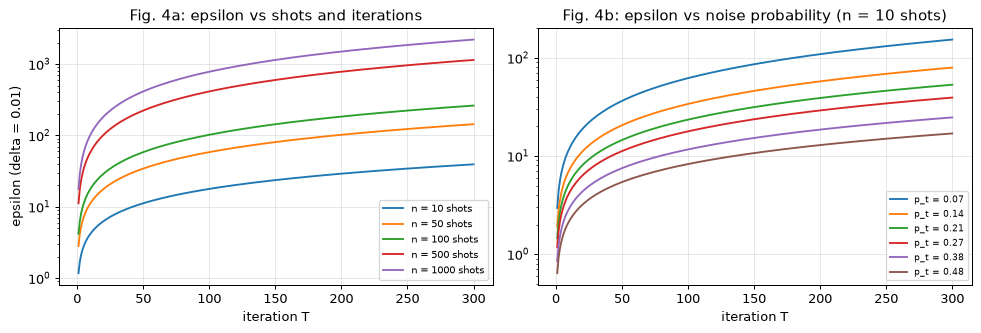

epsilon increases with shots: True; increases with iterations: True; decreases with p_t: True
 shots     z  epsilon at T=300
    10 2.730            39.379
    50 1.221           143.675
   100 0.863           262.180
   500 0.386          1143.640
  1000 0.273          2206.873



Largest number of shots per circuit that still meets the target at T = 300, delta = 0.01:
 target epsilon  max shots (paper noise)  max shots (2x noise)
              1                        0                     0
              2                        0                     0
              5                        0                     1
             10                        1                     4
             20                        3                    12
             50                       13                    44


In [18]:
B_BATCH = len(Xtr)
ALPHAS = np.concatenate([np.linspace(1.01, 10, 400), np.arange(11, 1024)])

def eps_rdp(z, T, delta=DELTA):
    z = np.asarray(z, float)[..., None]; T = np.asarray(T, float)[..., None] if np.ndim(T) else float(T)
    return np.min(T * ALPHAS / (2 * z ** 2) + np.log(1 / delta) / (ALPHAS - 1), axis=-1)

def z_paper(n, p):  return sigma_paper_lower(n, p) * math.sqrt(B_BATCH) / CLIP_C

# Is the clipping norm C = 0.7 a fair bound on the per-example gradient norm?  (paper: found by pre-training)
rng_c = np.random.default_rng(SEED + 4)
mx = []
for _ in range(60):
    thr = rng_c.uniform(-np.pi, np.pi, 4); mi_, _ = shifted_means(thr, Xtr, need_noisy=False)
    mx.append(np.linalg.norm((-0.5 * ytr[None, :] * (mi_[0::2] - mi_[1::2])), axis=0).max())
print(f"largest noise-free per-example gradient l2 norm over 60 random parameter vectors: {max(mx):.2f}; median of the maxima {np.median(mx):.2f}; "
      f"clipping norm C = {CLIP_C}")

tt = np.arange(1, T_ITERS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
eps_n = {}
for n in [10, 50, 100, 500, 1000]:
    e = eps_rdp(np.full(len(tt), z_paper(n, prof1)), tt); eps_n[n] = e; ax[0].semilogy(tt, e, label=f"n = {n} shots")
ax[0].set_xlabel("iteration T"); ax[0].set_ylabel(f"epsilon (delta = {DELTA})"); ax[0].set_title("Fig. 4a: epsilon vs shots and iterations"); ax[0].legend(fontsize=8)
eps_p = {}
for s in scales_sorted:
    e = eps_rdp(np.full(len(tt), z_paper(N10, PROF[s])), tt); eps_p[s] = e
    ax[1].semilogy(tt, e, label=f"p_t = {PROF[s]['p_t']:.2f}")
ax[1].set_xlabel("iteration T"); ax[1].set_title(f"Fig. 4b: epsilon vs noise probability (n = {N10} shots)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
eps_inc_shots = bool(np.all(np.diff([eps_n[n][-1] for n in [10, 50, 100, 500, 1000]]) > 0))
eps_inc_iter = bool(all(np.all(np.diff(e) > 0) for e in eps_n.values()))
eps_dec_noise = bool(np.all(np.diff([eps_p[s][-1] for s in scales_sorted]) < 0))
print(f"epsilon increases with shots: {eps_inc_shots}; increases with iterations: {eps_inc_iter}; decreases with p_t: {eps_dec_noise}")
print(pd.DataFrame({"shots": [10, 50, 100, 500, 1000], "z": [z_paper(n, prof1) for n in [10, 50, 100, 500, 1000]],
                    f"epsilon at T={T_ITERS}": [eps_n[n][-1] for n in [10, 50, 100, 500, 1000]]}).round(3).to_string(index=False))

# "A target privacy level can be achieved by choosing the number of runs": largest n whose epsilon (at T_ITERS) meets a target
n_all = np.arange(1, 20001)
def n_for_target(target, prof):
    ee = eps_rdp(np.array([z_paper(int(n), prof) for n in n_all]), T_ITERS)
    ok = np.where(ee <= target)[0]
    return int(n_all[ok.max()]) if len(ok) else 0
TARGET_TABLE = pd.DataFrame({"target epsilon": EPS_TARGETS,
                             "max shots (paper noise)": [n_for_target(e, prof1) for e in EPS_TARGETS],
                             "max shots (2x noise)": [n_for_target(e, PROF[2.0]) if 2.0 in PROF else np.nan for e in EPS_TARGETS]})
print(f"\nLargest number of shots per circuit that still meets the target at T = {T_ITERS}, delta = {DELTA}:")
print(TARGET_TABLE.to_string(index=False))

## 7. Beyond the paper: a membership-inference attack on the released gradient

A DP statement is a bound on what *any* adversary can learn. We test it with the strongest simple adversary: the attacker
knows the model parameters, all other training examples and the noise mechanism, sees the released (clipped, summed,
shot-noisy) gradient and must decide whether one chosen **target** example (the one with the largest gradient) was in
the batch. The attacker calibrates a diagonal likelihood-ratio statistic on simulated releases, then is scored on fresh
releases. The attack is run at the **worst-case parameters** (DP must hold at every parameter vector; at the converged
parameters all gradients are close to zero and nothing can be learned). If the inherent noise gives (epsilon, delta)-DP, then `TPR <= e^epsilon FPR + delta` must hold at every false-positive
rate; for a Gaussian mechanism the attack AUC is `Phi(mu / sqrt 2)` where `mu = ||mean difference|| / noise std`.

attack parameters: largest per-example gradient norm 1.39 (clipping norm 0.7)


 shots  target_grad_norm  AUC_attack  AUC_gaussian_prediction  eps_1step_paper  TPR@FPR=0.01  DP bound@0.01  TPR@FPR=0.05  DP bound@0.05  TPR@FPR=0.1  DP bound@0.1  bound violated
     1             1.385       0.541                    0.534             0.12         0.016          0.021         0.070          0.066        0.134         0.122           False
     5             1.385       0.567                    0.567             0.38         0.021          0.025         0.083          0.083        0.154         0.156           False
    10             1.385       0.592                    0.588             0.61         0.023          0.028         0.096          0.102        0.170         0.193           False
    50             1.385       0.669                    0.668             1.77         0.050          0.069         0.167          0.305        0.258         0.600           False
   100             1.385       0.731                    0.726             2.83         0.085        

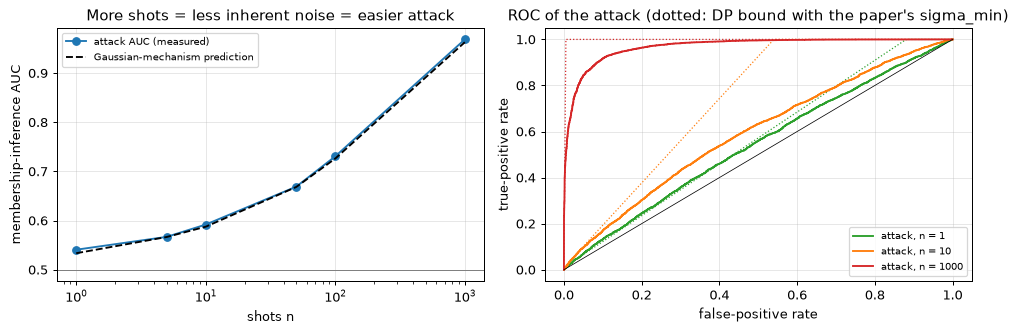

DP bound (paper sigma_min, one step, delta=0.01) respected at all tested points: True; max |AUC measured - Gaussian prediction| = 0.007


In [19]:
from scipy.stats import norm

def gauss_log_delta_terms(eps, mu):
    return norm.cdf(-eps / mu + mu / 2) - np.exp(eps + norm.logcdf(-eps / mu - mu / 2))

def gauss_eps(mu, delta=DELTA):
    """Exact epsilon of one Gaussian-mechanism step with mu = sensitivity / noise std (Balle & Wang 2018)."""
    if gauss_log_delta_terms(0.0, mu) <= delta:
        return 0.0
    return brentq(lambda e: gauss_log_delta_terms(e, mu) - delta, 0.0, 400.0)

def noisy_grad_sets(mi, y, n, trials, rng, gamma, C):
    p = np.clip((1 + mi / gamma) / 2, 0, 1)
    cnt = rng.binomial(n, p[None], size=(trials,) + p.shape)
    est = gamma * (2 * cnt / n - 1)
    G = np.transpose(-0.5 * y[None, None, :] * (est[:, 0::2, :] - est[:, 1::2, :]), (0, 2, 1))     # (trials, N, 4)
    nrm = np.linalg.norm(G, axis=2, keepdims=True)
    return G * np.minimum(1.0, C / np.maximum(nrm, 1e-12))

def run_mia(n, th, seed):
    rng = np.random.default_rng(seed)
    mi, _ = shifted_means(th, Xtr, need_noisy=False)
    mu_g = -0.5 * ytr[None, :] * (mi[0::2] - mi[1::2])
    t = int(np.argmax(np.linalg.norm(mu_g, axis=0)))                      # target = worst-case example
    Gc = noisy_grad_sets(mi, ytr, n, MIA_TRIALS, rng, GAMMA, CLIP_C)      # attacker's calibration releases
    S1c = Gc.sum(1); S0c = S1c - Gc[:, t, :]
    m1, m0, v = S1c.mean(0), S0c.mean(0), 0.5 * (S1c.var(0) + S0c.var(0)) + 1e-12
    w = (m1 - m0) / v
    GA = noisy_grad_sets(mi, ytr, n, MIA_TRIALS, rng, GAMMA, CLIP_C); GB = noisy_grad_sets(mi, ytr, n, MIA_TRIALS, rng, GAMMA, CLIP_C)
    pos = (GA.sum(1) - m0) @ w                                            # target in the batch
    neg = ((GB.sum(1) - GB[:, t, :]) - m0) @ w                            # target not in the batch
    score = np.r_[pos, neg]; lab = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
    fpr, tpr, _ = roc_curve(lab, score)
    mu_gdp = float(np.sqrt(np.sum((m1 - m0) ** 2 / v)))
    return dict(n=n, auc=float(roc_auc_score(lab, score)), fpr=fpr, tpr=tpr, mu=mu_gdp, auc_pred=float(norm.cdf(mu_gdp / math.sqrt(2))),
                gnorm=float(np.linalg.norm(mu_g[:, t])))

MIA_N = [1, 5, 10, 50, 100, 1000]
# CHOICE: DP must hold at every parameter vector, so the attack is run at the worst case among 200 random parameter vectors
# (largest per-example gradient norm), not at the converged parameters where all gradients are close to zero.
rng_t = np.random.default_rng(SEED + 5)
def _maxg(th):
    mi_, _ = shifted_means(th, Xtr, need_noisy=False)
    return np.linalg.norm(-0.5 * ytr[None, :] * (mi_[0::2] - mi_[1::2]), axis=0).max()
th_mia = max([rng_t.uniform(-np.pi, np.pi, 4) for _ in range(200)], key=_maxg)
print(f"attack parameters: largest per-example gradient norm {_maxg(th_mia):.2f} (clipping norm {CLIP_C})")
mia = {n: run_mia(n, th_mia, SEED + 10 + n) for n in MIA_N}
ALPHA_CHECK = [0.01, 0.05, 0.1]
rows = []
for n in MIA_N:
    r = mia[n]; eps1 = gauss_eps(1.0 / z_paper(n, prof1))
    row = dict(shots=n, target_grad_norm=round(r["gnorm"], 3), AUC_attack=round(r["auc"], 3), AUC_gaussian_prediction=round(r["auc_pred"], 3),
               eps_1step_paper=round(eps1, 2))
    viol = False
    for a in ALPHA_CHECK:
        tp = float(np.interp(a, r["fpr"], r["tpr"])); bd = min(1.0, math.exp(eps1) * a + DELTA)
        row[f"TPR@FPR={a}"] = round(tp, 3); row[f"DP bound@{a}"] = round(bd, 3)
        viol |= tp > bd + 3 * math.sqrt(bd * (1 - bd) / MIA_TRIALS)
    row["bound violated"] = bool(viol); rows.append(row)
MIA_TABLE = pd.DataFrame(rows)
print(MIA_TABLE.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(MIA_N, [mia[n]["auc"] for n in MIA_N], "o-", label="attack AUC (measured)")
ax[0].plot(MIA_N, [mia[n]["auc_pred"] for n in MIA_N], "k--", label="Gaussian-mechanism prediction")
ax[0].axhline(0.5, color="grey", lw=0.8); ax[0].set_xscale("log"); ax[0].set_xlabel("shots n"); ax[0].set_ylabel("membership-inference AUC")
ax[0].set_title("More shots = less inherent noise = easier attack"); ax[0].legend(fontsize=8)
for n, c in zip([1, 10, 1000], ["tab:green", "tab:orange", "tab:red"]):
    r = mia[n]; ax[1].plot(r["fpr"], r["tpr"], c, label=f"attack, n = {n}")
    e1 = gauss_eps(1.0 / z_paper(n, prof1)); xs_ = np.linspace(0, 1, 200); ax[1].plot(xs_, np.minimum(1, math.exp(e1) * xs_ + DELTA), c + "", ls=":", lw=1)
ax[1].plot([0, 1], [0, 1], "k-", lw=0.6); ax[1].set_xlabel("false-positive rate"); ax[1].set_ylabel("true-positive rate")
ax[1].set_title("ROC of the attack (dotted: DP bound with the paper's sigma_min)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
mia_ok = not MIA_TABLE["bound violated"].any()
auc_dev = float(np.max(np.abs(MIA_TABLE["AUC_attack"] - MIA_TABLE["AUC_gaussian_prediction"])))
print(f"DP bound (paper sigma_min, one step, delta={DELTA}) respected at all tested points: {mia_ok}; max |AUC measured - Gaussian prediction| = {auc_dev:.3f}")

## 8. Beyond the paper: inherent noise versus classical Gaussian-noise DP-SGD

Classical baselines on **exactly the same two scaled features**:

* non-private: random forest, SVC (RBF), logistic regression (and the noise-free QNN);
* a small classical model `g(x) = tanh(w.x + b)` with the same loss, clipping `C`, iterations `T` and batch, trained with
  **DP-SGD** (Gaussian noise `N(0, z^2 C^2)` added to the summed clipped gradients), with `z` chosen by the same accountant
  so that epsilon equals the target;
* the **same QNN** (noise-free exact gradients) trained with the same artificial Gaussian DP-SGD (Watkins et al. 2023);
* the QNN with **inherent noise only** (PEC, no artificial noise, clipping `C`), run with the largest number of shots whose
  paper-epsilon is at most the target.

Learning rate of the classical model: chosen on an inner validation split of the training data (the QNN keeps the paper's 0.01).
All final accuracies are test accuracies of the released parameters evaluated noise-free.

{'RandomForest': 1.0, 'SVC (rbf)': 1.0, 'LogisticRegression': 1.0, 'QNN noise-free (this notebook)': 1.0}


classical-model validation accuracy by learning rate: {0.003: np.float64(1.0), 0.01: np.float64(1.0), 0.03: np.float64(1.0), 0.1: np.float64(1.0)} -> chosen 0.1


(789 s)
 target_eps     z  classical_DPSGD  classical_sd  QNN_Gaussian_DPSGD  QNN_Gaussian_sd  loss_classical  loss_QNN_Gaussian  loss_QNN_inherent  shots_inherent  eps_inherent  QNN_inherent  QNN_inherent_sd
          1 4.013              1.0           0.0                 1.0              0.0           0.003              0.154                NaN               0           NaN           NaN              NaN
          2 3.363              1.0           0.0                 1.0              0.0           0.003              0.154                NaN               0           NaN           NaN              NaN
          5 2.553              1.0           0.0                 1.0              0.0           0.002              0.154                NaN               0           NaN           NaN              NaN
         10 1.989              1.0           0.0                 1.0              0.0           0.002              0.154              0.158               1         8.101           1.0     

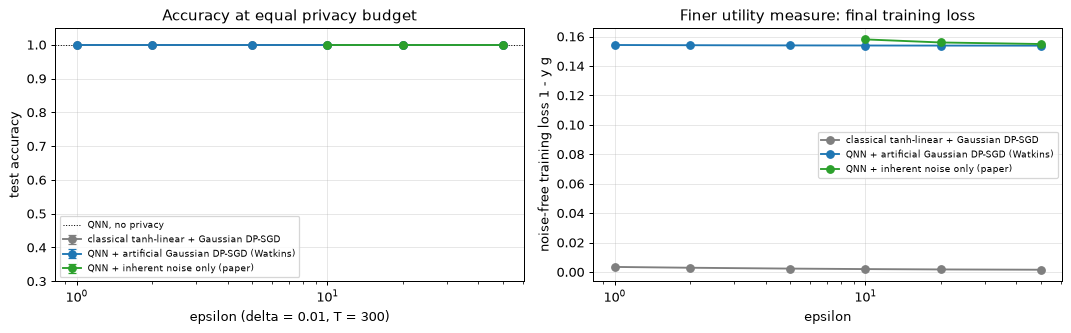

In [20]:
# non-private baselines on the identical 2-feature inputs
base = {}
for name, mdl in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED)),
                  ("SVC (rbf)", SVC(kernel="rbf", C=1.0, random_state=SEED)),
                  ("LogisticRegression", LogisticRegression(max_iter=1000, random_state=SEED))]:
    mdl.fit(Xtr, ytr); base[name] = float(mdl.score(Xte, yte))
base["QNN noise-free (this notebook)"] = float(H["ideal"][:, -1, 2].mean())
print({k: round(v, 3) for k, v in base.items()})

def train_classical(seed, T, lr, clip=None, z=None, X=Xtr, y=ytr, Xv=Xte, yv=yte):
    rng = np.random.default_rng(seed); w = np.random.default_rng(1000 + seed).normal(0, 0.5, 3)
    Xa = np.c_[X, np.ones(len(X))]
    for _ in range(T):
        g = np.tanh(Xa @ w); G = (-y * (1 - g ** 2))[:, None] * Xa
        if clip is not None: G = clip_rows(G, clip)
        gs = G.sum(0)
        if z is not None: gs = gs + rng.normal(0, z * clip, 3)
        w = w - lr * gs
    acc = float(np.mean(np.where(np.tanh(np.c_[Xv, np.ones(len(Xv))] @ w) >= 0, 1, -1) == yv))
    return acc, w, float(np.mean(1 - y * np.tanh(Xa @ w)))

# learning rate of the classical model: inner validation split of the training data only
Xi, Xv_, yi, yv_ = train_test_split(Xtr, ytr, test_size=0.25, stratify=ytr, random_state=SEED)
lr_scores = {lr: np.mean([train_classical(s, T_ITERS, lr, X=Xi, y=yi, Xv=Xv_, yv=yv_)[0] for s in range(3)]) for lr in [0.003, 0.01, 0.03, 0.1]}
LR_CLASSICAL = max(lr_scores, key=lambda k: (round(lr_scores[k], 6), k))
print("classical-model validation accuracy by learning rate:", {k: round(v, 3) for k, v in lr_scores.items()}, "-> chosen", LR_CLASSICAL)

def find_z(eps_target, T):
    return brentq(lambda lz: float(eps_rdp(np.array([math.exp(lz)]), T)[0]) - eps_target, math.log(0.05), math.log(500.0))

t0 = time.time()
dp_rows = []
th_acc = lambda th: predict_acc(Xte, yte, th, "ideal", 0, np.random.default_rng(0))
for eps_t in EPS_TARGETS:
    z = find_z(eps_t, T_ITERS)
    rc = [train_classical(s, T_ITERS, LR_CLASSICAL, clip=CLIP_C, z=z) for s in range(N_SEEDS)]
    acc_c, loss_c = [r[0] for r in rc], [r[2] for r in rc]
    thq = [train_qnn("ideal", s, T_ITERS, clip=CLIP_C, z=z, track=False)[0] for s in range(N_SEEDS)]
    acc_q, loss_q = [th_acc(t_) for t_ in thq], [ideal_loss(Xtr, ytr, t_) for t_ in thq]
    n_star = n_for_target(eps_t, prof1)
    if n_star >= 1:
        thi = [train_qnn("pec", s, T_ITERS, n=n_star, clip=CLIP_C, track=False)[0] for s in range(N_SEEDS)]
        acc_i, loss_i = [th_acc(t_) for t_ in thi], [ideal_loss(Xtr, ytr, t_) for t_ in thi]
        eps_i = float(eps_rdp(np.array([z_paper(n_star, prof1)]), T_ITERS)[0])
    else:
        acc_i, loss_i, eps_i = [np.nan] * N_SEEDS, [np.nan] * N_SEEDS, np.nan
    dp_rows.append(dict(target_eps=eps_t, z=z, classical_DPSGD=np.mean(acc_c), classical_sd=np.std(acc_c), QNN_Gaussian_DPSGD=np.mean(acc_q), QNN_Gaussian_sd=np.std(acc_q),
                        loss_classical=np.mean(loss_c), loss_QNN_Gaussian=np.mean(loss_q), loss_QNN_inherent=np.mean(loss_i),
                        shots_inherent=n_star, eps_inherent=eps_i, QNN_inherent=np.mean(acc_i), QNN_inherent_sd=np.std(acc_i)))
DPT = pd.DataFrame(dp_rows)
print(f"({time.time()-t0:.0f} s)"); print(DPT.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for col_, sd_, lc_, lab_, c_ in [("classical_DPSGD", "classical_sd", "loss_classical", "classical tanh-linear + Gaussian DP-SGD", "tab:gray"),
                                 ("QNN_Gaussian_DPSGD", "QNN_Gaussian_sd", "loss_QNN_Gaussian", "QNN + artificial Gaussian DP-SGD (Watkins)", "tab:blue"),
                                 ("QNN_inherent", "QNN_inherent_sd", "loss_QNN_inherent", "QNN + inherent noise only (paper)", "tab:green")]:
    ax[0].errorbar(DPT["target_eps"], DPT[col_], yerr=DPT[sd_], marker="o", capsize=3, label=lab_, color=c_)
    ax[1].plot(DPT["target_eps"], DPT[lc_], marker="o", label=lab_, color=c_)
ax[0].axhline(base["QNN noise-free (this notebook)"], color="k", ls=":", lw=0.8, label="QNN, no privacy")
ax[0].set_xscale("log"); ax[0].set_ylim(0.3, 1.05); ax[0].set_xlabel(f"epsilon (delta = {DELTA}, T = {T_ITERS})"); ax[0].set_ylabel("test accuracy")
ax[0].set_title("Accuracy at equal privacy budget"); ax[0].legend(fontsize=7)
ax[1].set_xscale("log"); ax[1].set_xlabel("epsilon"); ax[1].set_ylabel("noise-free training loss 1 - y g"); ax[1].set_title("Finer utility measure: final training loss"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Paper versus this notebook

The paper's Figs. 2 to 4 are vector graphics and the text gives **no numerical values**, so every comparison is of the
trend or the sign of an effect; "cannot be checked" marks what would need the paper's numbers.

In [21]:
def v_fmt(ok, yes="reproduced", no="not reached"):
    return yes if ok else no

def reg(f):   # mean loss over the run (speed of convergence), final loss, final noise-free test accuracy
    return {m: (f[m]["mean_loss_over_run"], f[m]["final_loss"], f[m]["acc_noise_free"]) for m in f}
rF, rS = reg(fin), reg(fin_lit)
slower_fast = (rF["noisy"][0] - rF["pec"][0]) > 0.02
slower_slow = (rS["noisy"][0] - rS["pec"][0]) > 0.02
_gap = rS["pec"][2] - rS["noisy"][2]
_se = max(fin_lit["noisy"]["acc_pipeline_sd"], fin_lit["pec"]["acc_pipeline_sd"]) / math.sqrt(N_SEEDS)
fail_slow = (_gap > 0.05) and (_gap > 2 * _se)             # needs a gap that is also larger than 2 standard errors over the seeds
txt_regime = lambda r: f"mean loss ideal/PEC/noisy {r['ideal'][0]:.3f}/{r['pec'][0]:.3f}/{r['noisy'][0]:.3f}, final {r['ideal'][1]:.3f}/{r['pec'][1]:.3f}/{r['noisy'][1]:.3f}"
upper_ratio = float(sigma_emp_pec(10, prof1).mean() / sigma_paper_upper(10, prof1))
gauss_ok_100 = bool(abs(GAUSS.loc[GAUSS.shots == 100, "skew"].iloc[0]) < 0.3 and abs(GAUSS.loc[GAUSS.shots == 100, "excess_kurtosis"].iloc[0]) < 0.5)
gauss_ok_10 = bool(abs(GAUSS.loc[GAUSS.shots == 10, "skew"].iloc[0]) < 0.3 and abs(GAUSS.loc[GAUSS.shots == 10, "excess_kurtosis"].iloc[0]) < 0.5)
auc_n1000 = mia[1000]["auc"]; auc_n1 = mia[1]["auc"]
inh = DPT.dropna(subset=["QNN_inherent"])
rows = [
 ("Fig. 2: unmitigated incoherent noise slows convergence",
  "qualitative (convergence slower / may fail)",
  f"fast regime: {txt_regime(rF)}; slow regime: {txt_regime(rS)}",
  ("reproduced in both regimes" if (slower_fast and slower_slow) else "reproduced in the slow regime only (training budget not exhausted)" if slower_slow
   else "reproduced in the fast regime only" if slower_fast else "not reached")),
 ("Fig. 2: without PEC the model may fail to converge; PEC restores it",
  "qualitative", f"final test accuracy (noise-free eval), slow regime: ideal {rS['ideal'][2]:.2f}, PEC {rS['pec'][2]:.2f}, noisy {rS['noisy'][2]:.2f}; fast regime: {rF['ideal'][2]:.2f}/{rF['pec'][2]:.2f}/{rF['noisy'][2]:.2f}",
  v_fmt(fail_slow, "reproduced", f"not conclusive (gap {_gap:+.2f} vs 2 s.e. {2*_se:.2f} over {N_SEEDS} seeds; noise damps <Z> but keeps its sign, so the noisy model reaches the same accuracy, only later)")),
 ("Gradient noise is Gaussian (shot noise + PEC)", "claimed from the CLT",
  f"skew/excess kurtosis at n=10: {GAUSS.loc[GAUSS.shots==10,'skew'].iloc[0]:.2f}/{GAUSS.loc[GAUSS.shots==10,'excess_kurtosis'].iloc[0]:.2f}; n=100: {GAUSS.loc[GAUSS.shots==100,'skew'].iloc[0]:.2f}/{GAUSS.loc[GAUSS.shots==100,'excess_kurtosis'].iloc[0]:.2f}",
  v_fmt(gauss_ok_100 and gauss_ok_10, "reproduced (n >= 10)", "reproduced for n >= 100 only" if gauss_ok_100 else "not reached")),
 ("Lemma 1: lower bound on the gradient variance (the one used for DP)", "proved",
  f"exact PEC std >= bound for every shot count and noise level: {lower_ok}; tightness at n=10: x{fa['pec_min'][3]/fa['lo'][3]:.1f}",
  v_fmt(lower_ok, "reproduced (valid, loose)")),
 ("Lemma 1: upper bound on the gradient variance", "proved",
  f"mean exact PEC std <= bound: {upper_ok}; at n=10 the exact mean std is x{upper_ratio:.2f} the paper's upper bound (sampled PEC has variance factor gamma^2, not sum|eta|^2)",
  v_fmt(upper_ok, "reproduced", "not reached for sampled PEC")),
 ("Fig. 3a: std decreases with the number of shots", "qualitative", f"bound decreases monotonically: {dec_shots}", v_fmt(dec_shots)),
 ("Fig. 3b: std lower bound increases with noise probability", "qualitative", f"bound increases monotonically: {inc_noise}", v_fmt(inc_noise)),
 ("Fig. 4a: epsilon increases with shots and iterations", "qualitative", f"eps(T={T_ITERS}) n=10 -> 1000: {eps_n[10][-1]:.1f} -> {eps_n[1000][-1]:.0f}; rises with T: {eps_inc_iter}", v_fmt(eps_inc_shots and eps_inc_iter)),
 ("Fig. 4b: epsilon decreases when the noise probability rises", "qualitative", f"eps(T={T_ITERS}, n=10) from p_t={PROF[scales_sorted[0]]['p_t']:.2f} to {PROF[scales_sorted[-1]]['p_t']:.2f}: {eps_p[scales_sorted[0]][-1]:.1f} -> {eps_p[scales_sorted[-1]][-1]:.1f}", v_fmt(eps_dec_noise)),
 ("A target epsilon can be reached by choosing the number of runs", "qualitative (delta = 0.01)",
  "max shots for eps<=" + ", ".join(f"{e}:{n}" for e, n in zip(TARGET_TABLE['target epsilon'], TARGET_TABLE['max shots (paper noise)'])) + f" (T={T_ITERS})",
  "reproduced (feasible); absolute epsilon values cannot be checked"),
 ("Numerical values of Figs. 2-4 (accuracy, std, epsilon)", "vector figures, not in the text", "see tables above", "cannot be checked"),
 ("[extra] membership inference respects the claimed DP bound", "not tested in the paper",
  f"bound respected: {mia_ok}; AUC n=1: {auc_n1:.2f}, n=1000: {auc_n1000:.2f}; max |AUC - Gaussian prediction| = {auc_dev:.3f}", v_fmt(mia_ok, "bound holds in the attack", "bound violated")),
 ("[extra] inherent noise vs Gaussian DP-SGD at equal epsilon", "not compared in the paper",
  "accuracy (inherent / QNN+Gaussian / classical+Gaussian) at " + "; ".join(f"eps {r.target_eps}: {r.QNN_inherent:.2f}/{r.QNN_Gaussian_DPSGD:.2f}/{r.classical_DPSGD:.2f}" for r in inh.itertuples()),
  "reported (no claim in the paper)"),
]
COMPARE = pd.DataFrame(rows, columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 140, "display.width", 250)
print(COMPARE.to_string(index=False))

                                                              Claim                                       Paper                                                                                                                                                        This notebook                                                                                                                                               Verdict
             Fig. 2: unmitigated incoherent noise slows convergence qualitative (convergence slower / may fail) fast regime: mean loss ideal/PEC/noisy 0.165/0.164/0.167, final 0.154/0.154/0.154; slow regime: mean loss ideal/PEC/noisy 0.476/0.476/0.562, final 0.160/0.160/0.208                                                                                    reproduced in the slow regime only (training budget not exhausted)
Fig. 2: without PEC the model may fail to converge; PEC restores it                                 qualitative                                   

## 10. Reading the paper critically

* **A bound, not a measurement.** The privacy budget is computed from a *lower bound* on the variance (`h_min` at
  `|<Z>| = 1`). Section 5 prints how loose that is for this circuit (ratio of the exact PEC std to the bound).
  A tighter calculation is possible but the DP accounting then depends on the task and the circuit.
* **Upper bound of Lemma 1.** Eq. (13) uses `sum_i |eta_i|^2` as variance factor of the mitigated estimator. That is the
  variance if each of the `K` circuit variants is estimated separately; the usual sampled PEC estimator has factor
  `gamma^2` (`gamma = sum |eta_i|`), which is larger. The lower bound used for DP stays valid (section 5), the upper bound does not.
* **Clipping norm.** `C = 0.7` is below the largest per-example gradient norm of this circuit at many parameter vectors
  (section 6 prints it), so clipping is active in training and is a real constraint, not a formality.
* **Clipping after noise.** Theorem 1 treats the clipped gradient plus Gaussian noise. On a real run the noise is added
  *before* clipping (the shots decide the gradient, which is then clipped), and clipping changes the noise distribution.
  The attack in section 7 clips the noisy gradient and still respects the bound, but this is an empirical check, not a proof.
* **The accountant is not specified.** "Composition like [6]" leaves open sub-sampling, the released quantity and the
  sensitivity. We fixed full-batch sums and Renyi-DP; a different convention changes epsilon by an order of magnitude.
  With these choices epsilon is large for many shots and small only for very few shots: the user must choose between
  accuracy of gradients and privacy.
* **Gaussianity and independence.** The CLT argument needs enough shots; the sum of PEC terms is a sum of two-point
  variables with values `+-gamma` and, at 1 to 10 shots, is visibly discrete. Different shots and different circuits must
  also be independent, which holds for ideal sampling but not for correlated device noise (drift, cross-talk).
* **Noise is not private randomness.** DP needs noise that the *adversary cannot reduce*. An observer of the hardware
  could repeat the experiment, characterise the device (it is the same noise every time) or, in a shared-cloud setting, see
  the raw counts. An adversary who knows the device noise and averages over many queries removes it, which is why the
  Gaussian-mechanism guarantee for the released gradient must be tied to a *single* release.
* **Gate noise is not global depolarising.** Section 5 shows the residual of `(1 - p_t) <Z>` with respect to the exact
  per-gate model; the model is a fair but not exact description, and the PEC overhead `gamma` grows exponentially with
  the number of gates, which limits the approach to shallow circuits.
* **PEC is itself noise-aware work.** Mitiq's PEC needs the noise model; here we gave PEC the exact depolarising rates,
  which a real user does not have. Mis-specified rates leave a bias that was not studied.
* **Toy task.** Setosa versus Versicolour is linearly separable; every classifier, private or not, reaches 100 % at almost
  every epsilon, so section 8 says little about the cost of privacy on a hard task. The test set has only 20 flowers.
* **No hardware.** All noise is simulated depolarising noise.

## Exercises

1. Change `LAM1, LAM2` to `0.01, 0.02` and rerun sections 4 to 6. How do `p_t`, `gamma` and the epsilon curve of Fig. 4b change?
   At which noise level is PEC so expensive (`gamma^2`) that inherent noise stops being "free"?
2. In section 6 replace the batch sum by the *mean* gradient (noise std `sigma_min / sqrt(B)`, sensitivity `C / B`). Show
   that epsilon is unchanged, then try the "per-example release" convention (`z = sigma_min / C`). How many orders of
   magnitude does epsilon change?
3. Remove the clipping in `noisy_grad_sets` and attack again. Is the bound with `C = 0.7` still respected when the largest
   gradient norm is above `C`? Print `mia[n]["gnorm"]`.
4. Make the attacker weaker (no knowledge of the other training examples) and stronger (query the same release 10 times and
   average). What does the second change do to the AUC for the same epsilon?
5. Replace `RX(pi x)` encoding by `RY(pi x)` or add a third layer to the ansatz. Does the exact variance of the gradient
   change, and is the lower bound still valid?